## Laboratorio 3

### Integrantes

1. Nicolas Mario Romero Colmenares - 202321309
2. Nicolas Rey 

## 1. Importaciones y Exploracion de datos

### 1.1 importacion de librerias

In [47]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.metrics import (make_scorer, f1_score, recall_score, precision_score, confusion_matrix)
from sklearn.model_selection import  RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import precision_recall_fscore_support

warnings.filterwarnings("ignore")

### 1.2 Carga de datos

Se carga el archivo Excel completo y se separan los dos subconjuntos de interés
según el tipo de cupón: Cafetería y Restaurante(<20).

In [2]:
RUTA = './Data/Lab3_Datos.xlsx'

pd.set_option("display.max_columns", None)

data = pd.read_excel(RUTA)

subsets = {
    "Cafeteria": data[data["cupon"] == "Cafetería"].copy(),
    "Restaurante(<20)": data[data["cupon"] == "Restaurante(<20)"].copy()
}

print(data.shape)
for nombre, s in subsets.items():
    print(nombre, s.shape)

(12664, 26)
Cafeteria (3986, 26)
Restaurante(<20) (2776, 26)


El dataset tiene 12.664 registros y 26 variables. Cafetería aporta 3.986 filas y Restaurante(<20) 2.776, es decir, entre ambos cubren cerca de la mitad de los datos.

### 1.3 Calidad de datos

Se revisan nulos, duplicados, columnas constantes, cardinalidad, valores fuera del diccionario, consistencia lógica entre variables y el perfil de cada subconjunto.

In [3]:
def calidad(s, nombre):
    print(f"{nombre}  |  filas: {len(s)}")

    # Nulos
    nulos = s.isna().sum()
    nulos = pd.DataFrame({"n_nulos": nulos, "%": (nulos / len(s) * 100).round(2)})
    print("\n-- Nulos --")
    print(nulos[nulos["n_nulos"] > 0].sort_values("%", ascending=False))

    # Duplicados
    print("\n-- Filas duplicadas exactas:", s.duplicated().sum())

    # Columnas constantes (no aportan información dentro del subconjunto)
    const = [c for c in s.columns if s[c].nunique(dropna=False) <= 1]
    print("-- Columnas constantes:", const)

    # Cardinalidad
    print("\n-- Cardinalidad --")
    print(s.nunique().sort_values(ascending=False))
    print(" ")

for nombre, s in subsets.items():
    calidad(s, nombre)

Cafeteria  |  filas: 3986

-- Nulos --
                                 n_nulos      %
vehiculo                            3949  99.07
frecuencia_cafeteria                  72   1.81
frecuencia_comida_para_llevar         57   1.43
frecuencia_restaurante_20_a_50        55   1.38
frecuencia_restaurante_menos_20       50   1.25
frecuencia_bar                        37   0.93

-- Filas duplicadas exactas: 7
-- Columnas constantes: ['cupon', 'tiempo_cupon_mayor_5min']

-- Cardinalidad --
ocupacion                          25
ingreso                             9
edad                                8
educacion                           6
estado_civil                        5
frecuencia_cafeteria                5
vehiculo                            5
frecuencia_comida_para_llevar       5
frecuencia_bar                      5
hora                                5
frecuencia_restaurante_20_a_50      5
frecuencia_restaurante_menos_20     5
acompanante                         4
destino           

`vehiculo` tiene ~99% de nulos en ambos subconjuntos y no es utilizable. Las variables `frecuencia_*` tienen menos de 2% de nulos. Hay 7 filas duplicadas en cada subconjunto. `cupon` y `tiempo_cupon_mayor_5min` son constantes y no aportan información.

In [4]:
validos = {
    "destino": ["Casa", "Sin lugar urgente", "Trabajo"],
    "acompanante": ["Solo", "Amigo(s)", "Hijo(s)", "Pareja"],
    "clima": ["Soleado", "Lluvioso", "Nevado"],
    "temperatura": [30, 55, 80],
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "vigencia_cupon": ["2 horas", "1 día"],
    "genero": ["Femenino", "Masculino"],
    "estado_civil": ["Soltero(a)", "Casado(a)", "Unión libre", "Divorciado(a)", "Viudo(a)"],
    "tiene_hijos": ["Sí", "No"],
    "vehiculo": ["Mazda5", "Scooter o motocicleta", "Camioneta tipo crossover",
                 "Carro muy viejo para instalarle Onstar", "No conduce"],
    "acepta_cupon": ["Sí", "No"],
    "misma_direccion": ["Sí", "No"],
    "direccion_opuesta": ["Sí", "No"],
    "tiempo_cupon_mayor_5min": ["Sí", "No"],
    "tiempo_cupon_mayor_15min": ["Sí", "No"],
    "tiempo_cupon_mayor_25min": ["Sí", "No"],
}
freq = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
for c in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
          "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]:
    validos[c] = freq

for nombre, s in subsets.items():
    print(f"\n--- {nombre}: valores fuera del diccionario ---")
    for col, ok in validos.items():
        if col not in s.columns:
            print(f"  [!] columna ausente: {col}")
            continue
        raros = set(s[col].dropna().unique()) - set(ok)
        if raros:
            print(f"  {col}: {raros}")


--- Cafeteria: valores fuera del diccionario ---
  vehiculo: {'Carro muy viejo para instalarle Onstar :D'}

--- Restaurante(<20): valores fuera del diccionario ---
  vehiculo: {'Carro muy viejo para instalarle Onstar :D'}


Solo se encontró una inconsistencia: en `vehiculo` aparece "Carro muy viejo para instalarle Onstar :D" (con ":D") en lugar del valor del diccionario. Debe homologarse antes de codificar.

In [5]:
for nombre, s in subsets.items():
    print(f"\n--- {nombre}: chequeos de consistencia ---")

    # clima <-> temperatura (diseño de la encuesta)
    print("\nclima vs temperatura:")
    print(pd.crosstab(s["clima"], s["temperatura"]))

    # misma_direccion y direccion_opuesta no pueden ser ambas 'Sí'
    both = ((s["misma_direccion"] == "Sí") & (s["direccion_opuesta"] == "Sí")).sum()
    print("\nmisma_direccion=Sí y direccion_opuesta=Sí a la vez:", both)
    print("(si son complementarias, una es redundante: revisa multicolinealidad)")
    print(pd.crosstab(s["misma_direccion"], s["direccion_opuesta"]))

    # Distancias anidadas: >25min implica >15min implica >5min
    inc = (
        ((s["tiempo_cupon_mayor_25min"] == "Sí") & (s["tiempo_cupon_mayor_15min"] == "No")) |
        ((s["tiempo_cupon_mayor_15min"] == "Sí") & (s["tiempo_cupon_mayor_5min"] == "No"))
    ).sum()
    print("\nFilas con distancias inconsistentes:", inc)

    # Hijos vs acompañante
    print("\ntiene_hijos vs acompanante='Hijo(s)':")
    print(pd.crosstab(s["tiene_hijos"], s["acompanante"]))


--- Cafeteria: chequeos de consistencia ---

clima vs temperatura:
temperatura   30    55    80
clima                       
Lluvioso       0   224     0
Nevado       303     0     0
Soleado       15  1049  2395

misma_direccion=Sí y direccion_opuesta=Sí a la vez: 0
(si son complementarias, una es redundante: revisa multicolinealidad)
direccion_opuesta   No    Sí
misma_direccion             
No                   0  3239
Sí                 747     0

Filas con distancias inconsistentes: 0

tiene_hijos vs acompanante='Hijo(s)':
acompanante  Amigo(s)  Hijo(s)  Pareja  Solo
tiene_hijos                                 
No                785        4     271  1381
Sí                440      203      32   870

--- Restaurante(<20): chequeos de consistencia ---

clima vs temperatura:
temperatura   30   55    80
clima                      
Lluvioso       0  170     0
Nevado       375    0     0
Soleado      172  493  1566

misma_direccion=Sí y direccion_opuesta=Sí a la vez: 0
(si son complemen

`misma_direccion` y `direccion_opuesta` son perfectamente complementarias (redundantes). Las distancias anidadas son coherentes (0 inconsistencias). `Nevado` solo ocurre a 30°F y `Lluvioso` a 55°F, pero `Soleado` aparece en las tres temperaturas.

In [6]:
for nombre, s in subsets.items():
    print(f"{nombre}")
    for col in ["destino", "acompanante", "clima", "hora", "vigencia_cupon",
                "genero", "edad", "ocupacion", "ingreso"]:
        print(f"\n{col}:")
        print(s[col].value_counts(dropna=False, normalize=True).mul(100).round(1))

Cafeteria

destino:
destino
Sin lugar urgente    54.0
Casa                 23.2
Trabajo              22.8
Name: proportion, dtype: float64

acompanante:
acompanante
Solo        56.5
Amigo(s)    30.7
Pareja       7.6
Hijo(s)      5.2
Name: proportion, dtype: float64

clima:
clima
Soleado     86.8
Nevado       7.6
Lluvioso     5.6
Name: proportion, dtype: float64

hora:
hora
6:00 p.m.     27.4
7:00 a.m.     22.8
10:00 a.m.    22.5
2:00 p.m.     19.9
10:00 p.m.     7.4
Name: proportion, dtype: float64

vigencia_cupon:
vigencia_cupon
2 horas    55.7
1 día      44.3
Name: proportion, dtype: float64

genero:
genero
Femenino     51.3
Masculino    48.7
Name: proportion, dtype: float64

edad:
edad
21             22.1
26             21.1
31             15.5
50 o más       13.6
36             10.1
41              8.1
46              5.5
menor de 21     3.9
Name: proportion, dtype: float64

ocupacion:
ocupacion
Desempleado(a)                                       14.3
Estudiante                   

Ambos subconjuntos son similares: predominan los trayectos sin lugar urgente, conductores solos y clima soleado. `ocupacion` tiene 25 categorías muy desiguales (algunas <1%) y requerirá agrupación.

### 1.4 Distribución de acepta_cupon en cada subconjunto

Se compara la distribución de la variable objetivo en cada subconjunto y su tasa de aceptación según las variables explicativas más relevantes.

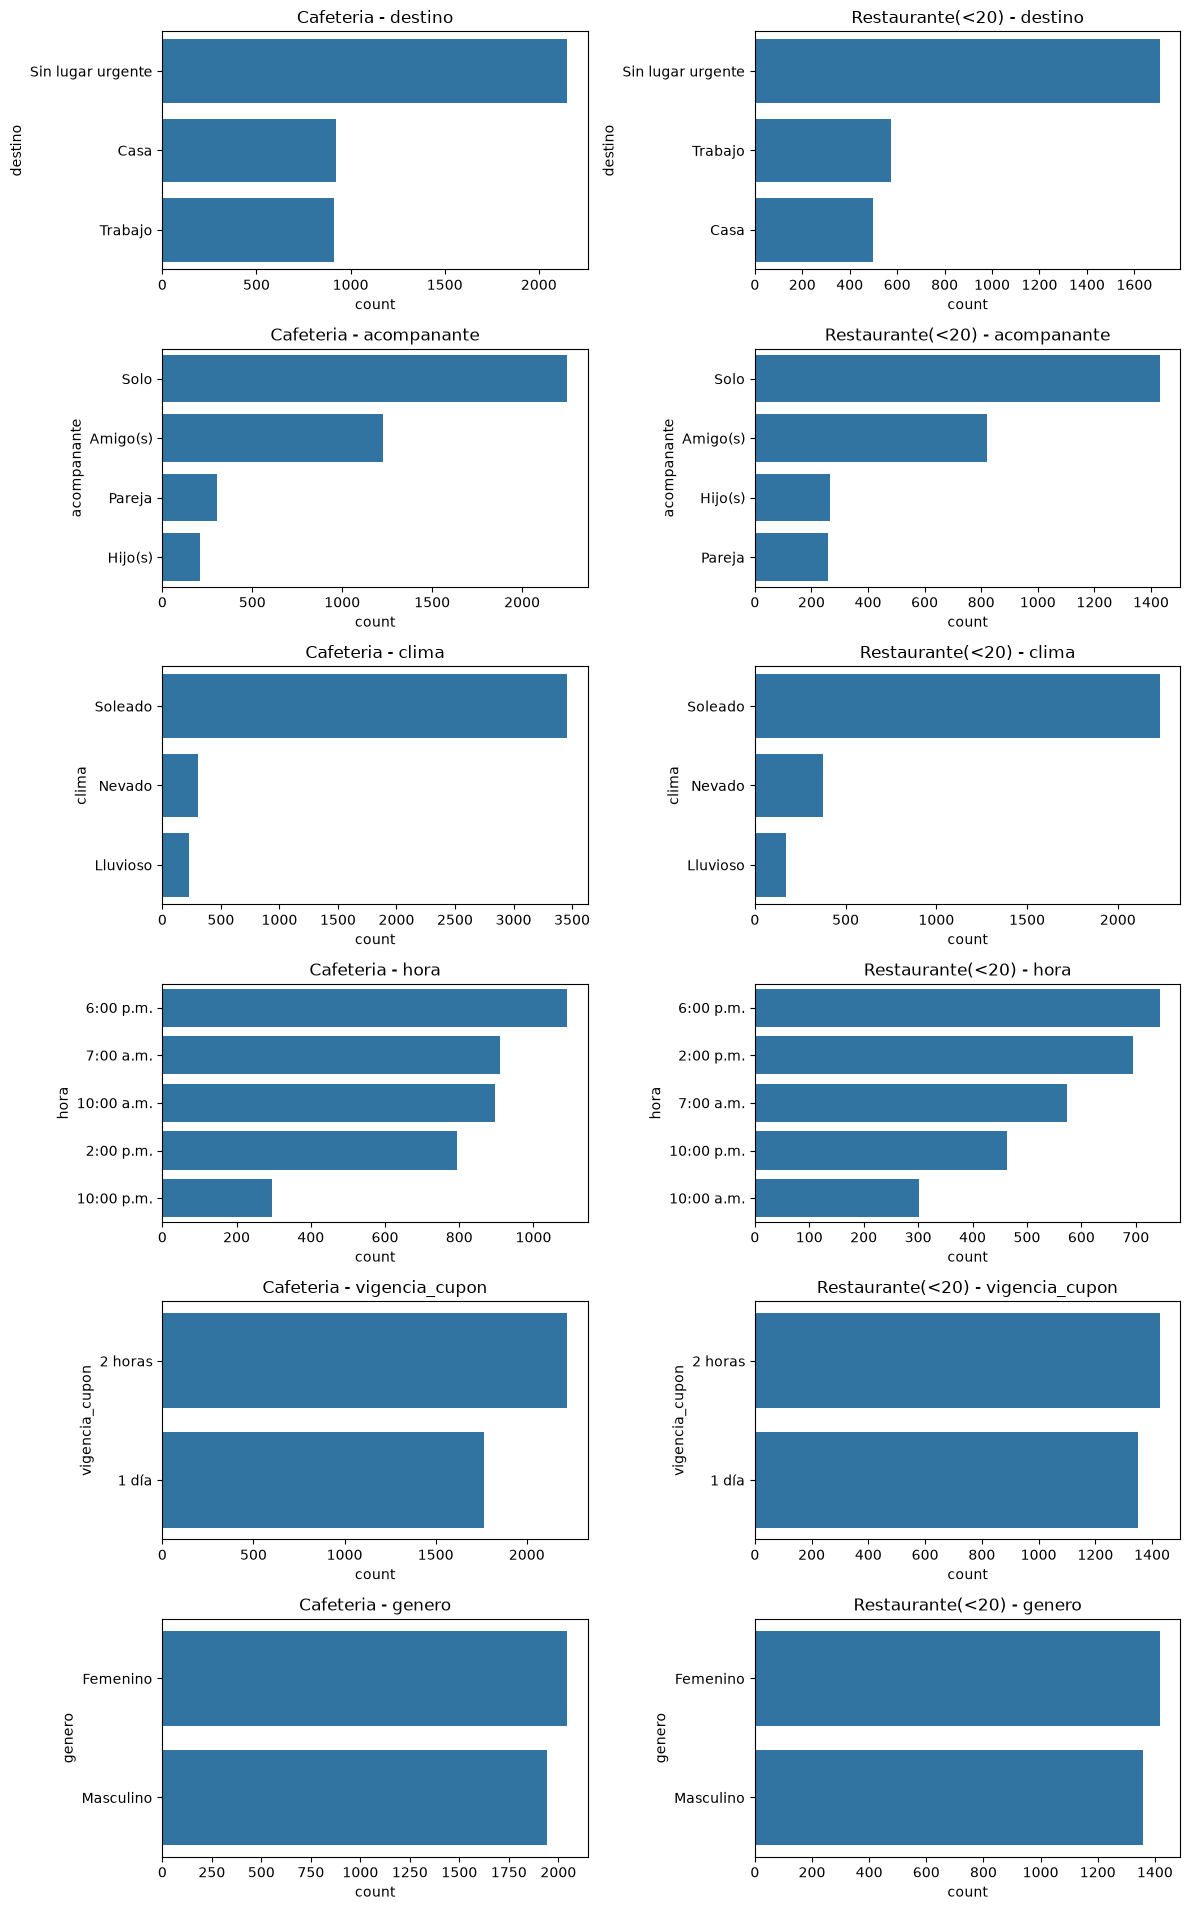

In [7]:
cols_plot = ["destino", "acompanante", "clima", "hora", "vigencia_cupon", "genero"]
fig, axes = plt.subplots(len(cols_plot), 2, figsize=(12, 3.2 * len(cols_plot)))

for i, col in enumerate(cols_plot):
    for j, (nombre, s) in enumerate(subsets.items()):
        sns.countplot(data=s, y=col, ax=axes[i, j],
                      order=s[col].value_counts().index)
        axes[i, j].set_title(f"{nombre} - {col}")
plt.tight_layout()
plt.show()

Las variables explicativas tienen distribuciones parecidas en ambos subconjuntos, con diferencias en `hora` y `clima` (mayor presencia de trayectos nevados y nocturnos en Restaurante(<20)).


Cafeteria
                 n     %
acepta_cupon            
No            1997  50.1
Sí            1989  49.9

Restaurante(<20)
                 n      %
acepta_cupon             
Sí            1962  70.68
No             814  29.32


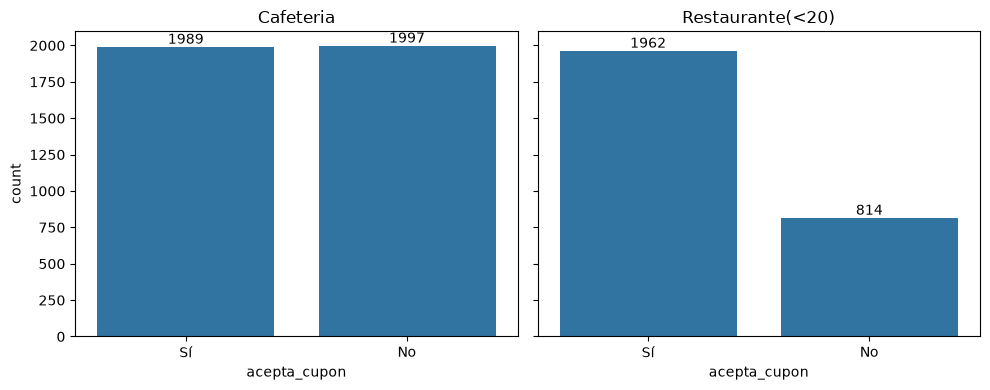

In [8]:
resumen = []
for nombre, s in subsets.items():
    vc = s["acepta_cupon"].value_counts(dropna=False)
    pct = s["acepta_cupon"].value_counts(dropna=False, normalize=True).mul(100).round(2)
    print(f"\n{nombre}")
    print(pd.DataFrame({"n": vc, "%": pct}))
    resumen.append(pct.rename(nombre))

# Gráfico lado a lado
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (nombre, s) in zip(axes, subsets.items()):
    sns.countplot(data=s, x="acepta_cupon", order=["Sí", "No"], ax=ax)
    ax.set_title(nombre)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout()
plt.show()

Cafetería está balanceada (49,9% Sí / 50,1% No), mientras que Restaurante(<20) está desbalanceada hacia la aceptación (70,7% Sí / 29,3% No). Esto afectará la elección de métricas y el entrenamiento de los modelos.

In [9]:
def tasa_aceptacion(s, col, orden=None):
    t = (s.assign(acepta=(s["acepta_cupon"] == "Sí").astype(int))
           .groupby(col)["acepta"].agg(["mean", "count"]))
    t["mean"] = (t["mean"] * 100).round(1)
    t = t.rename(columns={"mean": "% acepta", "count": "n"})
    return t.reindex(orden) if orden else t

for nombre, s in subsets.items():
    print(f"{nombre}")
    for col in ["vigencia_cupon", "hora", "clima", "destino", "acompanante",
                "tiempo_cupon_mayor_15min", "direccion_opuesta"]:
        print(f"\n{col}")
        print(tasa_aceptacion(s, col))

# Relación con la frecuencia de visita (ordinal)
print("\nCafetería ~ frecuencia_cafeteria")
print(tasa_aceptacion(subsets["Cafeteria"], "frecuencia_cafeteria", freq))
print("\nRestaurante(<20) ~ frecuencia_restaurante_menos_20")
print(tasa_aceptacion(subsets["Restaurante(<20)"], "frecuencia_restaurante_menos_20", freq))

Cafeteria

vigencia_cupon
                % acepta     n
vigencia_cupon                
1 día               58.4  1764
2 horas             43.2  2222

hora
            % acepta     n
hora                      
10:00 a.m.      64.0   897
10:00 p.m.      42.0   295
2:00 p.m.       54.7   793
6:00 p.m.       41.2  1091
7:00 a.m.       44.7   910

clima
          % acepta     n
clima                   
Lluvioso      51.8   224
Nevado        43.2   303
Soleado       50.4  3459

destino
                   % acepta     n
destino                          
Casa                   36.1   925
Sin lugar urgente      58.0  2151
Trabajo                44.7   910

acompanante
             % acepta     n
acompanante                
Amigo(s)         59.6  1225
Hijo(s)          48.3   207
Pareja           56.8   303
Solo             43.8  2251

tiempo_cupon_mayor_15min
                          % acepta     n
tiempo_cupon_mayor_15min                
No                            54.8  1917
Sí            

En ambos subconjuntos aceptan más los cupones de 1 día, con destino "sin lugar urgente" y los conductores con mayor frecuencia de visita. En cambio, `direccion_opuesta` tiene efecto inverso entre subconjuntos, así que conviene modelarlos por separado.

## 2. Limpieza y preparacion de datos

Con base en los hallazgos de la exploración, se eliminan variables inútiles, se tratan duplicados y nulos, se agrupan categorías raras y se codifican las variables para modelar.

### 2.1 Eliminacion de datos

In [10]:
COLS_ELIMINAR = ["vehiculo", "cupon", "tiempo_cupon_mayor_5min", "direccion_opuesta"]

def limpiar(s):
    s = s.drop_duplicates()            # primero duplicados, con todas las columnas originales
    s = s.drop(columns=COLS_ELIMINAR)
    return s.reset_index(drop=True)

clean = {n: limpiar(s) for n, s in subsets.items()}

for n, s in clean.items():
    print(f"{n}: {subsets[n].shape} -> {s.shape}")

Cafeteria: (3986, 26) -> (3979, 22)
Restaurante(<20): (2776, 26) -> (2769, 22)


In [11]:
UMBRAL = 3.0   # % mínimo para conservar la categoría

freq_ocup = pd.concat(clean.values())["ocupacion"].value_counts(normalize=True).mul(100)
principales = freq_ocup[freq_ocup >= UMBRAL].index.tolist()
print(f"Categorías conservadas ({len(principales)}):", principales)

for n, s in clean.items():
    s["ocupacion"] = s["ocupacion"].where(s["ocupacion"].isin(principales), "Otras")
    print(n, "->", s["ocupacion"].nunique(), "categorías de ocupación")

Categorías conservadas (10): ['Desempleado(a)', 'Estudiante', 'Computación y Matemáticas', 'Ventas y afines', 'Educación, Formación y Bibliotecología', 'Gerencia', 'Artes, Diseño, Entretenimiento, Deportes y Medios', 'Apoyo Administrativo y de Oficina', 'Jubilado(a)', 'Negocios y Finanzas']
Cafeteria -> 11 categorías de ocupación
Restaurante(<20) -> 11 categorías de ocupación


### 2.2 Codificacion

In [12]:
ORDINALES = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo",
                  "Estudios universitarios sin título", "Técnico/Tecnólogo",
                  "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499",
                "$37.500 - $49.999", "$50.000 - $62.499", "$62.500 - $74.999",
                "$75.000 - $87.499", "$87.500 - $99.999", "$100.000 o más"],
    **{c: freq for c in ["frecuencia_bar", "frecuencia_cafeteria",
                         "frecuencia_comida_para_llevar",
                         "frecuencia_restaurante_menos_20",
                         "frecuencia_restaurante_20_a_50"]},
}
BINARIAS = ["tiene_hijos", "misma_direccion",
            "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min"]
NOMINALES = ["destino", "acompanante", "clima", "estado_civil", "ocupacion", "genero"]

def codificar(s):
    s = s.copy()

    for col, orden in ORDINALES.items():
        mapa = {v: i for i, v in enumerate(orden)}
        cod = s[col].map(lambda v: mapa.get(str(v)) if pd.notna(v) else np.nan)
        sin_mapa = s.loc[s[col].notna() & cod.isna(), col].unique()
        if len(sin_mapa):
            raise ValueError(f"'{col}': valores sin mapear {sin_mapa}")
        s[col] = cod.astype(float)

    for col in BINARIAS + ["acepta_cupon"]:
        s[col] = s[col].map({"Sí": 1, "No": 0})
        assert s[col].notna().all(), f"nulos inesperados en {col}"

    # NUEVO: vigencia_cupon como binaria (1 = vigencia de 1 día)
    s["vigencia_cupon"] = s["vigencia_cupon"].map({"2 horas": 0, "1 día": 1})
    assert s["vigencia_cupon"].notna().all(), "valores inesperados en vigencia_cupon"

    s = pd.get_dummies(s, columns=NOMINALES, drop_first=True, dtype=int)

    # Verificación: no debe quedar ninguna columna de texto
    no_num = s.select_dtypes(exclude="number").columns.tolist()
    assert not no_num, f"columnas sin codificar: {no_num}"
    return s

prep = {n: codificar(s) for n, s in clean.items()}

for n, s in prep.items():
    print(f"{n}: {s.shape}, nulos restantes: {s.isna().sum().sum()}")

Cafeteria: (3979, 38), nulos restantes: 271
Restaurante(<20): (2769, 38), nulos restantes: 174


### 2.3 Justificacion de la preparacion de datos

| Desicion | Evidencia de la exploracion | Justificacion |
| --- | --- | --- |
| Eliminar la columna vehiculo | 99% de nulos en ambos subconjuntos | No hay información suficiente para imputar de forma razonable |
| Eliminar columnas cupon y tiempo_cupon_mayor_5min | Constantes en ambos subconjuntos | Sin varianza no aportan al análisis ni a un modelo |
| Eliminar columna direccion_opuesta | Es el complemento exacto de misma_direccion | Es redundante y generaría multicolinealidad perfecta | 
| Eliminar 7 duplicados por subconjunto | 7 filas duplicadas exactas en cada uno | No hay identificador de encuestado, así que no se pueden distinguir de un registro repetido. El impacto es mínimo|
| Imputar con la moda las frecuencias | Menos de 2% de nulos cada una | Eliminar filas perdería muestra, y con tan pocos nulos la moda introduce un sesgo mínimo. Se ajusta solo con entrenamiento para no filtrar información|
| Conservar temperatura junto a clima | Soleado aparece en 30°F, 55°F y 80°F | No es redundante con clima, porque distingue días soleados fríos y cálidos |
| Agrupar ocupacion en pocas categorias | 25 categorías, varias con menos de 2% | Evita columnas casi vacías al codificar y reduce el riesgo de sobreajuste |
| Codificar ordinales con enteros | hora, edad, educacion, ingreso y las frecuencias tienen orden natural | Conserva la relación de orden sin multiplicar columnas |
| Codificar nominales con one-hot y binarias con 0/1 | destino, acompanante, clima, estado_civil, ocupacion, genero tienen si o Sí/No | Estas variables no tienen orden |
| Mantener los dos subconjuntos separados y usar partición estratificada | Cafetería 49,9% Sí y Restaurante 70,7% Sí | Los comportamientos difieren, y estratificar mantiene la proporción de la clase objetivo en entrenamiento y prueba |
| No tocar las filas con tiene_hijos=No y acompanante=Hijo | Solo 4 y 3 casos | Pueden ser sobrinos o nietos, y el efecto es despreciable |
| No tratar valores atípicos | No hay variables numéricas continuas (temperatura solo toma 3 valores) | No aplica |
| Codificar vigencia_cupon como binaria | Dos categorías; es el factor con mayor efecto en la aceptación | Al tener solo dos niveles, una columna 0/1 basta y evita crear una dummy equivalente |

Se eliminaron 4 columnas y 7 duplicados por subconjunto, se imputaron los nulos de `frecuencia_*` con la moda (solo entrenamiento) y se codificaron las variables. La partición estratificada conserva el balance de `acepta_cupon` (~50% Cafetería, ~71% Restaurante).

### 3 Modelos de regresion logistica

Se entrena una regresión logística por tipo de cupón dentro de un Pipeline (imputación con moda, escalado y modelo). GridSearchCV con 5 folds estratificados evalúa 90 combinaciones de regularización, solver, C y class_weight, y selecciona por ROC-AUC.

### 3.1 Particion de datos

In [13]:
splits = {}
for n, s in prep.items():
    X, y = s.drop(columns="acepta_cupon"), s["acepta_cupon"]
    splits[n] = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    print(n, "| train:", splits[n][0].shape, "| test:", splits[n][1].shape)

Cafeteria | train: (3183, 37) | test: (796, 37)
Restaurante(<20) | train: (2215, 37) | test: (554, 37)


Partición estratificada 80/20: Cafetería con 3.183 filas de entrenamiento y 796 de prueba, Restaurante(<20) con 2.215 y 554, ambas con 37 variables predictoras. La estratificación mantiene la proporción de aceptación en ambos conjuntos.

### 3.2 Pipeline

In [14]:
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=42)),
])

Cs = [0.01, 0.1, 1, 10, 100]
pesos = [None, "balanced"]

param_grid = [
    {"clf__solver": ["liblinear"], "clf__penalty": ["l1", "l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["saga"], "clf__penalty": ["l1", "l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["saga"], "clf__penalty": ["elasticnet"],
     "clf__l1_ratio": [0.25, 0.5, 0.75],
     "clf__C": Cs, "clf__class_weight": pesos},
    {"clf__solver": ["lbfgs", "newton-cg"], "clf__penalty": ["l2"],
     "clf__C": Cs, "clf__class_weight": pesos},
]

La imputación y el escalado quedan dentro del pipeline, así que se ajustan solo con los datos de entrenamiento de cada fold. Esto evita fuga de información hacia el fold de validación.

### 3.3 Busqueda con validacion cruzada

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy"}

modelos = {}
for n, (X_tr, X_te, y_tr, y_te) in splits.items():
    gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="roc_auc",
                      cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    modelos[n] = gs
    print(f"\n{n}")
    print("  Mejores hiperparámetros:", gs.best_params_)
    print(f"  ROC-AUC CV: {gs.best_score_:.4f}")


Cafeteria
  Mejores hiperparámetros: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0.25, 'clf__penalty': 'elasticnet', 'clf__solver': 'saga'}
  ROC-AUC CV: 0.7743

Restaurante(<20)
  Mejores hiperparámetros: {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l1', 'clf__solver': 'saga'}
  ROC-AUC CV: 0.7397


Cafetería: saga con elasticnet (l1_ratio=0,25), C=0,1 y class_weight='balanced', ROC-AUC CV = 0,7743. Restaurante(<20): saga con l1, C=0,1 y sin class_weight, ROC-AUC CV = 0,7397. En ambos casos C=0,1 indica una regularización relativamente fuerte.

### 3.5 Resultados de busqueda

In [16]:
cols = ["param_clf__solver", "param_clf__penalty", "param_clf__C",
        "param_clf__class_weight", "mean_test_roc_auc",
        "mean_test_f1", "mean_test_accuracy"]

for n, gs in modelos.items():
    res = pd.DataFrame(gs.cv_results_)
    print(f"\n{n} - Top 5 combinaciones")
    print(res.sort_values("rank_test_roc_auc")[cols].head(5).round(4).to_string(index=False))

    print(f"\n{n} - Mejor ROC-AUC por solver y penalización")
    print(res.groupby(["param_clf__solver", "param_clf__penalty"])["mean_test_roc_auc"]
             .max().round(4))


Cafeteria - Top 5 combinaciones
param_clf__solver param_clf__penalty  param_clf__C param_clf__class_weight  mean_test_roc_auc  mean_test_f1  mean_test_accuracy
             saga         elasticnet           0.1                balanced             0.7743        0.7092              0.7110
             saga         elasticnet           0.1                     NaN             0.7743        0.7079              0.7103
             saga                 l1           1.0                balanced             0.7743        0.7067              0.7085
        liblinear                 l1           1.0                balanced             0.7742        0.7072              0.7091
        liblinear                 l1           1.0                     NaN             0.7742        0.7064              0.7085

Cafeteria - Mejor ROC-AUC por solver y penalización
param_clf__solver  param_clf__penalty
lbfgs              l2                    0.7741
liblinear          l1                    0.7742
            

El solver casi no importa: la diferencia entre solvers es ≤0,002 de ROC-AUC (0,7741–0,7743 en Cafetería, 0,7380–0,7397 en Restaurante), porque optimizan la misma función. En Restaurante, l1 supera ligeramente a l2. class_weight='balanced' no mejora el AUC y baja la accuracy CV de 0,760 a 0,711.

El poder discriminante es moderado (ROC-AUC 0,77 y 0,74). En Cafetería la accuracy CV es 0,711 (vs 0,50 de azar); en Restaurante(<20) es 0,760, solo ~5 puntos sobre el 70,7% de la clase mayoritaria.

### 3.6 Coeficientes

In [17]:
for n, gs in modelos.items():
    cols_X = splits[n][0].columns
    coef = pd.Series(gs.best_estimator_.named_steps["clf"].coef_[0], index=cols_X)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
    print(f"\n{n} - 10 coeficientes de mayor magnitud")
    print(top.round(3))
    print("Coeficientes en 0 (eliminados por regularización):", int((coef == 0).sum()))


Cafeteria - 10 coeficientes de mayor magnitud
frecuencia_cafeteria         0.966
destino_Sin lugar urgente    0.506
vigencia_cupon               0.386
hora                        -0.380
misma_direccion              0.255
frecuencia_bar              -0.224
tiempo_cupon_mayor_15min    -0.207
acompanante_Solo            -0.165
estado_civil_Unión libre    -0.146
tiempo_cupon_mayor_25min     0.135
dtype: float64
Coeficientes en 0 (eliminados por regularización): 2

Restaurante(<20) - 10 coeficientes de mayor magnitud
vigencia_cupon                     0.542
clima_Soleado                      0.341
destino_Sin lugar urgente          0.333
acompanante_Hijo(s)               -0.210
acompanante_Solo                  -0.188
educacion                         -0.156
temperatura                        0.128
frecuencia_restaurante_menos_20    0.128
estado_civil_Soltero(a)            0.119
hora                              -0.113
dtype: float64
Coeficientes en 0 (eliminados por regularización): 11


Cafetería: pesan más frecuencia_cafeteria (0,97), destino "sin lugar urgente" (0,51) y vigencia (0,39). Restaurante(<20): vigencia (0,54), clima soleado (0,34) y destino (0,33); l1 dejó 11 de 37 coeficientes en 0 (2 en Cafetería). Coincide con la exploración, aunque la frecuencia de visita pesa mucho menos en Restaurante (0,13).

### 3.7 Evaluación en el conjunto de prueba


Cafeteria (regresión logística)
              precision    recall  f1-score   support

          No       0.69      0.68      0.69       399
          Sí       0.69      0.70      0.69       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796

ROC-AUC (test): 0.7295

Restaurante(<20) (regresión logística)
              precision    recall  f1-score   support

          No       0.66      0.36      0.47       162
          Sí       0.78      0.92      0.84       392

    accuracy                           0.76       554
   macro avg       0.72      0.64      0.66       554
weighted avg       0.74      0.76      0.74       554

ROC-AUC (test): 0.7402


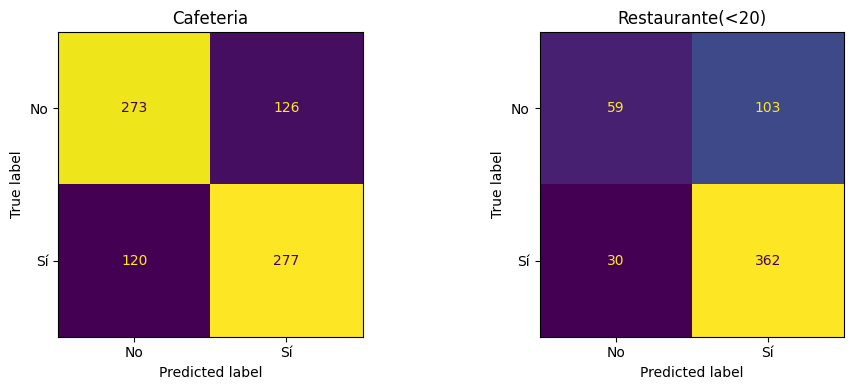

In [56]:
for n, gs in modelos.items():
    X_tr, X_te, y_tr, y_te = splits[n]
    y_pred = gs.predict(X_te)
    y_prob = gs.predict_proba(X_te)[:, 1]
    print(f"\n{'='*60}\n{n} (regresión logística)\n{'='*60}")
    print(classification_report(y_te, y_pred, target_names=["No", "Sí"]))
    print(f"ROC-AUC (test): {roc_auc_score(y_te, y_prob):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (n, gs) in zip(axes, modelos.items()):
    X_te, y_te = splits[n][1], splits[n][3]
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_te, y_te,
                                          display_labels=["No", "Sí"], ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.show()

En Cafetería la regresión logística tiene accuracy de 0,69 y un recall parejo entre clases (0,68 para "No" y 0,70 para "Sí"), con ROC-AUC de 0,730 en prueba. En Restaurante(<20) la accuracy es de 0,76, pero eso engaña porque la clase mayoritaria ya es el 70,8%. El recall de "No" es de solo 0,36 frente a 0,92 de "Sí": el modelo acierta casi todas las aceptaciones y deja pasar dos de cada tres rechazos (F1 de "No" = 0,47, ROC-AUC = 0,740). Es la misma limitación que se vio con el árbol y que se retoma en la sección 6.

## 4. Arboles de desicion

Se entrena un árbol de decisión por tipo de cupón dentro de un Pipeline. GridSearchCV con 5 folds explora criterio, profundidad máxima, mínimo de muestras por hoja y class_weight (180 combinaciones), seleccionando por ROC-AUC.

### 4.1 Pipeline y espacio de hiperparámetros

In [19]:
pipe_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("clf", DecisionTreeClassifier(random_state=42)),
])

param_grid_tree = {
    "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__max_depth": [3, 5, 7, 10, 15, None],
    "clf__min_samples_leaf": [1, 5, 10, 20, 50],
    "clf__class_weight": [None, "balanced"],
}

### 4.2 Busqueda con validacion cruzada

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy"}

arboles = {}
for n, (X_tr, X_te, y_tr, y_te) in splits.items():
    gs = GridSearchCV(pipe_tree, param_grid_tree, scoring=scoring, refit="roc_auc",
                      cv=cv, n_jobs=-1, return_train_score=True)
    gs.fit(X_tr, y_tr)
    arboles[n] = gs
    print(f"\n{n}")
    print("  Mejores hiperparámetros:", gs.best_params_)
    print(f"  ROC-AUC CV: {gs.best_score_:.4f}")


Cafeteria
  Mejores hiperparámetros: {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 50}
  ROC-AUC CV: 0.7647

Restaurante(<20)
  Mejores hiperparámetros: {'clf__class_weight': None, 'clf__criterion': 'gini', 'clf__max_depth': 7, 'clf__min_samples_leaf': 20}
  ROC-AUC CV: 0.7431


Se entrena un árbol de decisión por tipo de cupón dentro de un Pipeline. GridSearchCV con 5 folds explora criterio, profundidad máxima, mínimo de muestras por hoja y class_weight (180 combinaciones), seleccionando por ROC-AUC.

### 4.3 Resultados de busqueda

In [23]:
cols = ["param_clf__criterion", "param_clf__max_depth", "param_clf__min_samples_leaf",
        "param_clf__class_weight", "mean_test_roc_auc", "mean_train_roc_auc",
        "mean_test_f1", "mean_test_accuracy"]

for n, gs in arboles.items():
    res = pd.DataFrame(gs.cv_results_)
    print(f"{n} - Top 5 combinaciones \n")
    print(res.sort_values("rank_test_roc_auc")[cols].head(5).round(4).to_string(index=False))

    # Efecto de cada hiperparámetro: mejor ROC-AUC CV según su valor
    for p in ["criterion", "max_depth", "min_samples_leaf", "class_weight"]:
        col = f"param_clf__{p}"
        print(f"\n{n} - Mejor ROC-AUC CV por {p}")
        print(res.groupby(res[col].astype(str))["mean_test_roc_auc"].max().round(4).to_string())

    # Sobreajuste del mejor modelo
    b = res.loc[gs.best_index_]
    print(f"\n{n} - ROC-AUC entrenamiento: {b['mean_train_roc_auc']:.4f} | "
          f"validación: {b['mean_test_roc_auc']:.4f} | "
          f"brecha: {b['mean_train_roc_auc'] - b['mean_test_roc_auc']:.4f}")

Cafeteria - Top 5 combinaciones 

param_clf__criterion param_clf__max_depth  param_clf__min_samples_leaf param_clf__class_weight  mean_test_roc_auc  mean_train_roc_auc  mean_test_f1  mean_test_accuracy
                gini                 None                           50                balanced             0.7647              0.8035        0.7097              0.7088
                gini                   10                           50                balanced             0.7647              0.8035        0.7097              0.7088
                gini                   15                           50                balanced             0.7647              0.8035        0.7097              0.7088
                gini                   15                           50                     NaN             0.7646              0.8035        0.7058              0.7081
                gini                   10                           50                     NaN             0.7646             

Los árboles muy superficiales subajustan (max_depth=3: 0,725 y 0,713) y la ganancia se estabiliza desde profundidad 7. En Cafetería, max_depth 10, 15 y None empatan porque min_samples_leaf=50 ya limita el crecimiento. entropy y log_loss son idénticos y quedan entre 0,003 y 0,008 por debajo de gini.

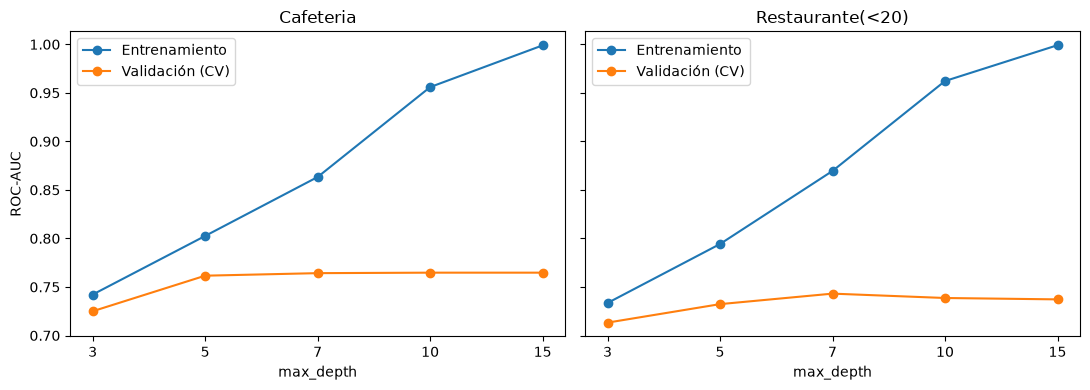

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (n, gs) in zip(axes, arboles.items()):
    res = pd.DataFrame(gs.cv_results_)
    res["profundidad"] = res["param_clf__max_depth"].astype(str)
    orden = ["3", "5", "7", "10", "15", "None"]
    g = res.groupby("profundidad")[["mean_train_roc_auc", "mean_test_roc_auc"]].max().reindex(orden)
    ax.plot(orden, g["mean_train_roc_auc"], marker="o", label="Entrenamiento")
    ax.plot(orden, g["mean_test_roc_auc"], marker="o", label="Validación (CV)")
    ax.set_title(n)
    ax.set_xlabel("max_depth")
    ax.legend()
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout()
plt.show()

La brecha entre ROC-AUC de entrenamiento y validación es 0,039 en Cafetería (0,804 vs 0,765) y 0,066 en Restaurante(<20) (0,809 vs 0,743). Hay sobreajuste leve en el primero y moderado en el segundo, controlado por la poda mediante min_samples_leaf y max_depth.

### 4.4 Evaluacion en el conjunto de prueba


Cafeteria (árbol)
              precision    recall  f1-score   support

          No       0.70      0.66      0.68       399
          Sí       0.68      0.72      0.70       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796

ROC-AUC (test): 0.7509

Restaurante(<20) (árbol)
              precision    recall  f1-score   support

          No       0.67      0.38      0.48       162
          Sí       0.78      0.92      0.85       392

    accuracy                           0.76       554
   macro avg       0.73      0.65      0.66       554
weighted avg       0.75      0.76      0.74       554

ROC-AUC (test): 0.7069


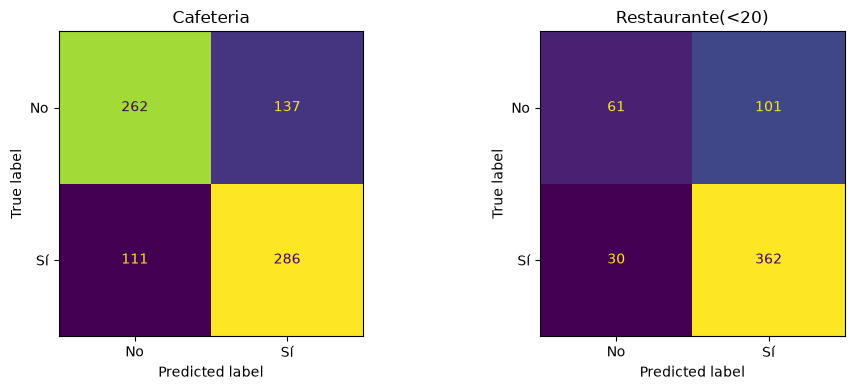

In [25]:
for n, gs in arboles.items():
    X_tr, X_te, y_tr, y_te = splits[n]
    y_pred = gs.predict(X_te)
    y_prob = gs.predict_proba(X_te)[:, 1]
    print(f"\n{'='*60}\n{n} (árbol)\n{'='*60}")
    print(classification_report(y_te, y_pred, target_names=["No", "Sí"]))
    print(f"ROC-AUC (test): {roc_auc_score(y_te, y_prob):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (n, gs) in zip(axes, arboles.items()):
    X_te, y_te = splits[n][1], splits[n][3]
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_te, y_te,
                                          display_labels=["No", "Sí"], ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.show()

Cafetería: ROC-AUC = 0,751 y accuracy 0,69, con recall parejo entre clases (0,66 No / 0,72 Sí).  Restaurante(<20): ROC-AUC = 0,707 y accuracy 0,76 (la clase mayoritaria ya es 70,8%), con recall de 'No' de solo 0,38 frente a 0,92 de 'Sí': el árbol casi no detecta los rechazos, reflejo del desbalance.

### 4.5 Importancia de variables y estructura del árbol

In [26]:
for n, gs in arboles.items():
    cols_X = splits[n][0].columns
    imp = pd.Series(gs.best_estimator_.named_steps["clf"].feature_importances_, index=cols_X)
    print(f"\n{n} - 10 variables más importantes")
    print(imp.sort_values(ascending=False).head(10).round(3))
    print("Variables sin uso en el árbol:", int((imp == 0).sum()))


Cafeteria - 10 variables más importantes
frecuencia_cafeteria              0.519
destino_Sin lugar urgente         0.112
misma_direccion                   0.076
hora                              0.073
vigencia_cupon                    0.073
ingreso                           0.036
educacion                         0.020
frecuencia_restaurante_20_a_50    0.020
edad                              0.015
acompanante_Solo                  0.014
dtype: float64
Variables sin uso en el árbol: 21

Restaurante(<20) - 10 variables más importantes
tiempo_cupon_mayor_25min         0.319
hora                             0.118
vigencia_cupon                   0.109
frecuencia_comida_para_llevar    0.051
acompanante_Solo                 0.050
edad                             0.048
frecuencia_bar                   0.045
frecuencia_cafeteria             0.045
ingreso                          0.032
acompanante_Hijo(s)              0.029
dtype: float64
Variables sin uso en el árbol: 15


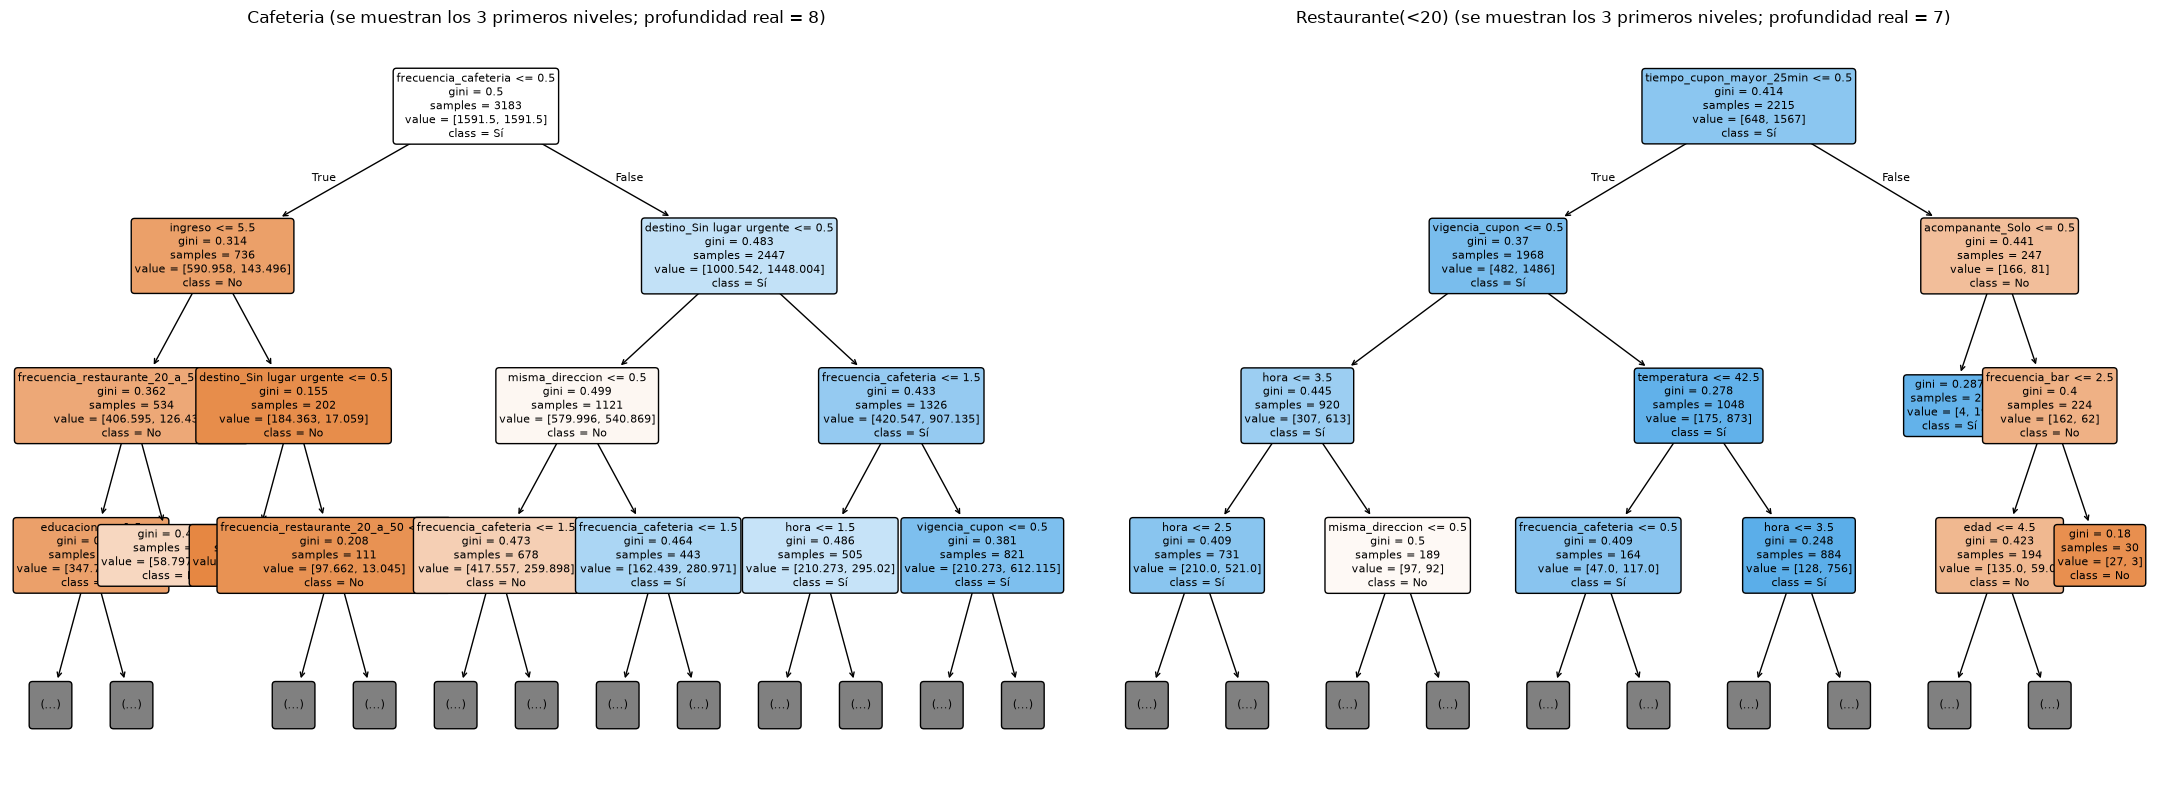

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, (n, gs) in zip(axes, arboles.items()):
    clf = gs.best_estimator_.named_steps["clf"]
    plot_tree(clf, feature_names=splits[n][0].columns, class_names=["No", "Sí"],
              max_depth=3, filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"{n} (se muestran los 3 primeros niveles; profundidad real = {clf.get_depth()})")
plt.tight_layout()
plt.show()

Cafetería depende sobre todo de frecuencia_cafeteria (0,52), seguida de destino "sin lugar urgente" (0,11) y de misma_direccion, hora y vigencia (~0,07 cada una); 21 de 37 variables no se usan. En Restaurante(<20) domina tiempo_cupon_mayor_25min (0,32), seguida de hora (0,12) y vigencia (0,11); 15 variables sin uso.

### 4.6 Comparacion con la regresion logistica

In [28]:
filas = []
for n in splits:
    X_te, y_te = splits[n][1], splits[n][3]
    for nombre, gs in [("Regresión logística", modelos[n]), ("Árbol de decisión", arboles[n])]:
        filas.append({
            "subconjunto": n, "modelo": nombre,
            "ROC-AUC CV": round(gs.best_score_, 4),
            "ROC-AUC test": round(roc_auc_score(y_te, gs.predict_proba(X_te)[:, 1]), 4),
            "Accuracy test": round((gs.predict(X_te) == y_te).mean(), 4),
        })
display(pd.DataFrame(filas))

,subconjunto,modelo,ROC-AUC CV,ROC-AUC test,Accuracy test
0,Cafeteria,Regresión logística,0.7743,0.7295,0.6910
1,Cafeteria,Árbol de decisión,0.7647,0.7509,0.6884
2,Restaurante(<20),Regresión logística,0.7397,0.7402,0.7599
3,Restaurante(<20),Árbol de decisión,0.7431,0.7069,0.7635


Ningún modelo gana de forma consistente. En Cafetería el árbol es peor en CV (0,765 vs 0,774) pero mejor en prueba (0,751 vs 0,730); en Restaurante(<20) es ligeramente mejor en CV (0,743 vs 0,740) pero peor en prueba (0,707 vs 0,740). La accuracy es casi igual (0,69 y 0,76), así que las diferencias caen dentro del ruido de conjuntos de prueba pequeños. Como el desempeño es similar, la regresión logística resulta preferible por su estabilidad entre CV y prueba, sobre todo en Restaurante(<20). El árbol aporta reglas legibles, pero es más sensible a la partición de los datos.

## 5. Desarrollo de modelos Random Forest

Se entrena un Random Forest por tipo de cupón dentro de un Pipeline (imputación y modelo). GridSearchCV con 5 folds explora número de árboles, profundidad máxima, mínimo de muestras por hoja y class_weight (120 combinaciones), seleccionando por ROC-AUC, igual que en los modelos anteriores.

### 5.1 Pipeline y espacio de hiperparámetros

In [30]:
pipe_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
])

param_grid_rf = {
    "clf__n_estimators": [100, 300, 500],
    "clf__max_depth": [5, 10, 15, None],
    "clf__min_samples_leaf": [1, 5, 10, 20, 50],
    "clf__class_weight": [None, "balanced"],
}

### 5.2 Busqueda con validacion cruzada

In [31]:
bosques = {}
for n, (X_tr, X_te, y_tr, y_te) in splits.items():
    gs = GridSearchCV(pipe_rf, param_grid_rf, scoring=scoring, refit="roc_auc",
                      cv=cv, n_jobs=-1, return_train_score=True)
    gs.fit(X_tr, y_tr)
    bosques[n] = gs
    print(f"\n{n}")
    print("  Mejores hiperparámetros:", gs.best_params_)
    print(f"  ROC-AUC CV: {gs.best_score_:.4f}")


Cafeteria
  Mejores hiperparámetros: {'clf__class_weight': None, 'clf__max_depth': 15, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}
  ROC-AUC CV: 0.8379

Restaurante(<20)
  Mejores hiperparámetros: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}
  ROC-AUC CV: 0.7865


Cafetería: 500 árboles, max_depth=15, min_samples_leaf=1 y sin class_weight (ROC-AUC CV = 0,8379). Restaurante(<20): 500 árboles, sin límite de profundidad, min_samples_leaf=1 y class_weight='balanced' (ROC-AUC CV = 0,7865). Ambos superan con holgura al árbol individual (0,765 y 0,743).

### 5.3 Resultados de busqueda

In [38]:
cols = ["param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf",
        "param_clf__class_weight", "mean_test_roc_auc", "mean_train_roc_auc",
        "mean_test_f1", "mean_test_accuracy"]

for n, gs in bosques.items():
    res = pd.DataFrame(gs.cv_results_)
    print(f"{n} - Top 5 combinaciones\n")
    print(res.sort_values("rank_test_roc_auc")[cols].head(5).round(4).to_string(index=False))

    for p in ["n_estimators", "max_depth", "min_samples_leaf", "class_weight"]:
        col = f"param_clf__{p}"
        print(f"\n{n} - Mejor ROC-AUC CV por {p}")
        print(res.groupby(res[col].astype(str))["mean_test_roc_auc"].max().round(4).to_string())

    b = res.loc[gs.best_index_]
    print(f"\n{n} - ROC-AUC entrenamiento: {b['mean_train_roc_auc']:.4f} | "
          f"validación: {b['mean_test_roc_auc']:.4f} | "
          f"brecha: {b['mean_train_roc_auc'] - b['mean_test_roc_auc']:.4f}")

Cafeteria - Top 5 combinaciones

 param_clf__n_estimators param_clf__max_depth  param_clf__min_samples_leaf param_clf__class_weight  mean_test_roc_auc  mean_train_roc_auc  mean_test_f1  mean_test_accuracy
                     500                   15                            1                     NaN             0.8379                 1.0        0.7626              0.7609
                     500                 None                            1                     NaN             0.8376                 1.0        0.7610              0.7606
                     300                   15                            1                     NaN             0.8373                 1.0        0.7631              0.7619
                     500                 None                            1                balanced             0.8371                 1.0        0.7621              0.7622
                     300                 None                            1                     NaN         

El número de árboles apenas importa: de 100 a 500 el ROC-AUC sube ~0,003–0,004, y de 300 a 500 casi nada. La profundidad sí influye (max_depth=5: 0,789 y 0,765; 15 o más: 0,838 y 0,787). A diferencia del árbol individual, gana min_samples_leaf=1 y el rendimiento cae al aumentarlo (0,782 y 0,751 con 50).

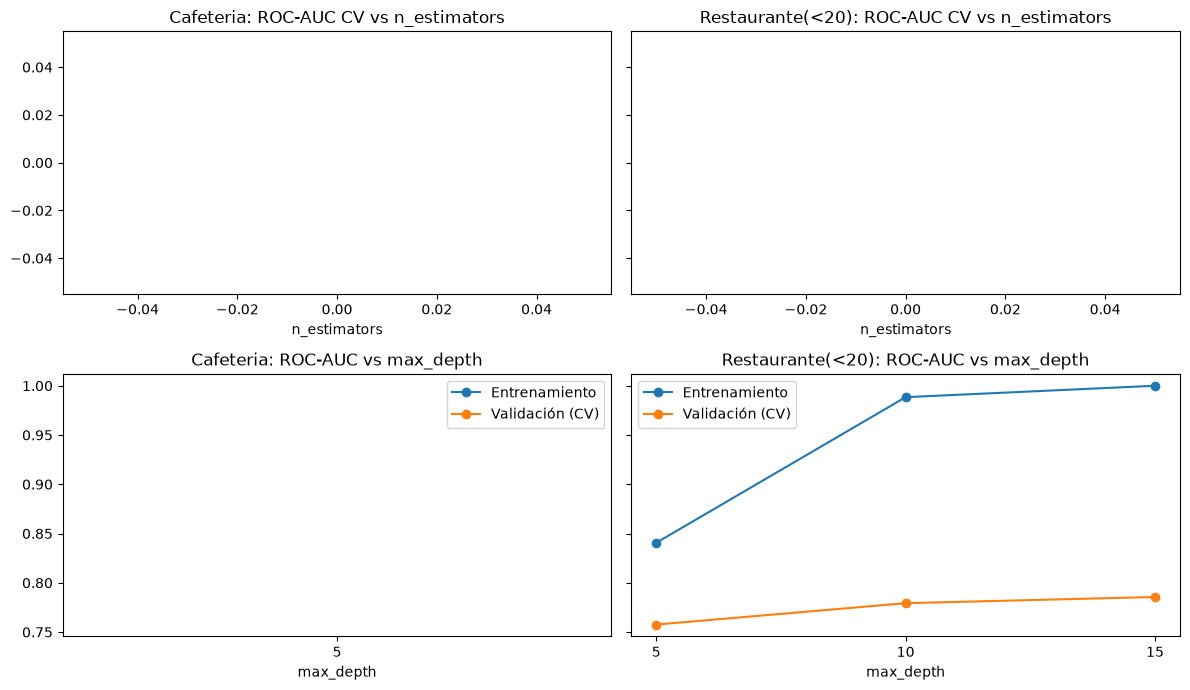

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey="row")
for j, (n, gs) in enumerate(bosques.items()):
    res = pd.DataFrame(gs.cv_results_)
    bp = gs.best_params_

    m = res[(res["param_clf__max_depth"].astype(str) == str(bp["clf__max_depth"])) &
            (res["param_clf__min_samples_leaf"] == bp["clf__min_samples_leaf"]) &
            (res["param_clf__class_weight"].astype(str) == str(bp["clf__class_weight"]))]
    axes[0, j].plot(m["param_clf__n_estimators"].astype(int), m["mean_test_roc_auc"], marker="o")
    axes[0, j].set_title(f"{n}: ROC-AUC CV vs n_estimators")
    axes[0, j].set_xlabel("n_estimators")

    m = res[(res["param_clf__n_estimators"] == bp["clf__n_estimators"]) &
            (res["param_clf__min_samples_leaf"] == bp["clf__min_samples_leaf"]) &
            (res["param_clf__class_weight"].astype(str) == str(bp["clf__class_weight"]))]
    orden = ["5", "10", "15", "None"]
    g = m.assign(d=m["param_clf__max_depth"].astype(str)).set_index("d").reindex(orden)
    axes[1, j].plot(orden, g["mean_train_roc_auc"], marker="o", label="Entrenamiento")
    axes[1, j].plot(orden, g["mean_test_roc_auc"], marker="o", label="Validación (CV)")
    axes[1, j].set_title(f"{n}: ROC-AUC vs max_depth")
    axes[1, j].set_xlabel("max_depth")
    axes[1, j].legend()
plt.tight_layout()
plt.show()

class_weight no cambia el ROC-AUC (0,8379 vs 0,8371 en Cafetería; 0,7865 en ambos en Restaurante). El ROC-AUC de entrenamiento llega a 1,00 frente a 0,838 y 0,787 en validación (brechas de 0,162 y 0,214): es esperable con árboles profundos y hojas de 1 muestra, y lo relevante es que la validación supera a la de los otros modelos.

### 5.4 Evaluacion en el conjunto de prueba


Cafeteria (Random Forest)
              precision    recall  f1-score   support

          No       0.78      0.76      0.77       399
          Sí       0.77      0.79      0.78       397

    accuracy                           0.77       796
   macro avg       0.77      0.77      0.77       796
weighted avg       0.77      0.77      0.77       796

ROC-AUC (test): 0.8414

Restaurante(<20) (Random Forest)
              precision    recall  f1-score   support

          No       0.61      0.57      0.59       162
          Sí       0.83      0.85      0.84       392

    accuracy                           0.77       554
   macro avg       0.72      0.71      0.71       554
weighted avg       0.76      0.77      0.76       554

ROC-AUC (test): 0.7837


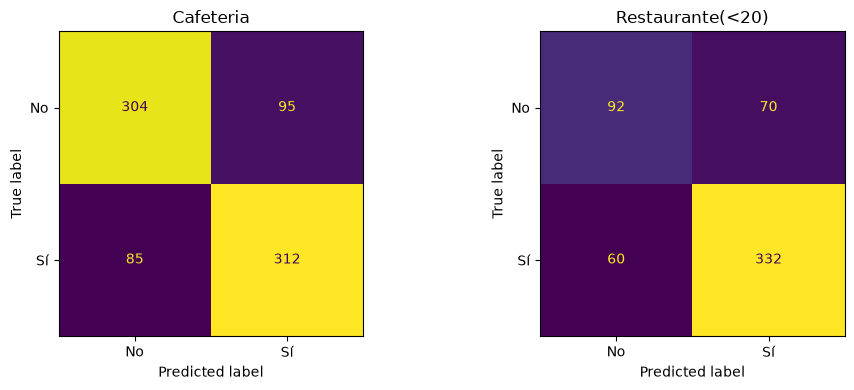

In [35]:
for n, gs in bosques.items():
    X_tr, X_te, y_tr, y_te = splits[n]
    y_pred = gs.predict(X_te)
    y_prob = gs.predict_proba(X_te)[:, 1]
    print(f"\n{'='*60}\n{n} (Random Forest)\n{'='*60}")
    print(classification_report(y_te, y_pred, target_names=["No", "Sí"]))
    print(f"ROC-AUC (test): {roc_auc_score(y_te, y_prob):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (n, gs) in zip(axes, bosques.items()):
    X_te, y_te = splits[n][1], splits[n][3]
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_te, y_te,
                                          display_labels=["No", "Sí"], ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.show()

En prueba, Cafetería obtiene ROC-AUC = 0,841 y accuracy 0,77, con recall equilibrado (0,76 No / 0,79 Sí). Restaurante(<20) obtiene ROC-AUC = 0,784 y accuracy 0,77 (clase mayoritaria: 70,8%); el recall de 'No' sube a 0,57 frente a 0,38 del árbol. Ambos resultados son consistentes con los de CV (0,838 y 0,787).

### 5.5 Importancia de variables

In [36]:
for n, gs in bosques.items():
    X_tr, X_te, y_tr, y_te = splits[n]
    cols_X = X_tr.columns

    imp = pd.Series(gs.best_estimator_.named_steps["clf"].feature_importances_, index=cols_X)
    perm = permutation_importance(gs.best_estimator_, X_te, y_te, scoring="roc_auc",
                                  n_repeats=10, random_state=42, n_jobs=-1)
    perm = pd.Series(perm.importances_mean, index=cols_X)

    comp = pd.DataFrame({"impureza": imp, "permutación (caída de AUC)": perm})
    print(f"\n{n} - 10 variables más importantes (por impureza)")
    print(comp.sort_values("impureza", ascending=False).head(10).round(3))
    print(f"\n{n} - 10 variables más importantes (por permutación)")
    print(comp.sort_values("permutación (caída de AUC)", ascending=False).head(10).round(3))


Cafeteria - 10 variables más importantes (por impureza)
                                 impureza  permutación (caída de AUC)
frecuencia_cafeteria                0.164                       0.181
ingreso                             0.071                       0.023
edad                                0.064                       0.016
hora                                0.052                       0.015
educacion                           0.052                       0.019
frecuencia_bar                      0.049                       0.015
frecuencia_comida_para_llevar       0.047                       0.010
frecuencia_restaurante_20_a_50      0.046                       0.011
frecuencia_restaurante_menos_20     0.046                       0.010
vigencia_cupon                      0.042                       0.019

Cafeteria - 10 variables más importantes (por permutación)
                                impureza  permutación (caída de AUC)
frecuencia_cafeteria               0.164    

En Cafetería, frecuencia_cafeteria domina con ambos métodos (impureza 0,16; caída de AUC por permutación 0,18), muy por encima del resto (≤0,02). En Restaurante(<20) la impureza reparte el peso entre ingreso, hora y edad, pero por permutación destaca vigencia_cupon (0,038). La impureza sobrestima variables con muchos valores (frecuencia_cafeteria: 0,063 vs 0,002).

### 5.6 Comparacion de los 3 modelos

In [37]:
filas = []
for n in splits:
    X_te, y_te = splits[n][1], splits[n][3]
    for nombre, gs in [("Regresión logística", modelos[n]),
                       ("Árbol de decisión", arboles[n]),
                       ("Random Forest", bosques[n])]:
        filas.append({
            "subconjunto": n, "modelo": nombre,
            "ROC-AUC CV": round(gs.best_score_, 4),
            "ROC-AUC test": round(roc_auc_score(y_te, gs.predict_proba(X_te)[:, 1]), 4),
            "Accuracy test": round((gs.predict(X_te) == y_te).mean(), 4),
        })
comparacion = pd.DataFrame(filas)
display(comparacion)

,subconjunto,modelo,ROC-AUC CV,ROC-AUC test,Accuracy test
0,Cafeteria,Regresión logística,0.7743,0.7295,0.6910
1,Cafeteria,Árbol de decisión,0.7647,0.7509,0.6884
2,Cafeteria,Random Forest,0.8379,0.8414,0.7739
3,Restaurante(<20),Regresión logística,0.7397,0.7402,0.7599
4,Restaurante(<20),Árbol de decisión,0.7431,0.7069,0.7635
5,Restaurante(<20),Random Forest,0.7865,0.7837,0.7653


Random Forest es el mejor modelo en ambos cupones: ROC-AUC de prueba 0,841 (Cafetería) y 0,784 (Restaurante(<20)), frente a 0,730/0,751 y 0,740/0,707 de regresión logística/árbol. En Cafetería la accuracy también sube (0,774 vs ~0,69); en Restaurante queda igual (~0,76–0,77), solo ~6 puntos sobre la clase mayoritaria.

Se selecciona Random Forest como modelo final por su mayor ROC-AUC en ambos cupones, con resultados estables entre CV y prueba. La ganancia sobre los modelos lineales sugiere relaciones no lineales o interacciones entre variables, sobre todo en Cafetería; el costo es menor interpretabilidad.

### 6. Balanceo de clases para Restaurantes(<20)

Se evalúa si balancear la clase minoritaria ("No", 29,3%) mejora el Random Forest de Restaurante(<20). Se comparan tres variantes con la misma validación cruzada y el mismo criterio de selección (F1 macro): sin balancear, class_weight='balanced' y SMOTE (aplicado solo a los folds de entrenamiento, dentro del pipeline, para evitar fuga de información).

### 6.1 Preparacion

In [41]:
nombre = "Restaurante(<20)"
X_tr, X_te, y_tr, y_te = splits[nombre]

print("Distribución en entrenamiento (0 = No, 1 = Sí):")
print(y_tr.value_counts().sort_index())
print(f"Clase minoritaria (No): {(y_tr == 0).mean():.1%}")

Distribución en entrenamiento (0 = No, 1 = Sí):
acepta_cupon
0     648
1    1567
Name: count, dtype: int64
Clase minoritaria (No): 29.3%


### 6.2 Pipelines y espacio de búsqueda

In [42]:
def crear_pipe(con_smote=False):
    pasos = [("imputer", SimpleImputer(strategy="most_frequent"))]
    if con_smote:
        pasos.append(("smote", SMOTE(random_state=42)))
    pasos.append(("clf", RandomForestClassifier(random_state=42, n_jobs=1)))
    return ImbPipeline(pasos)

grid_comun = {
    "clf__n_estimators": [300],
    "clf__max_depth": [10, 15, None],
    "clf__min_samples_leaf": [1, 5, 10],
}

variantes = {
    "Sin balancear": (crear_pipe(), {**grid_comun, "clf__class_weight": [None]}),
    "class_weight='balanced'": (crear_pipe(), {**grid_comun, "clf__class_weight": ["balanced"]}),
    "SMOTE": (crear_pipe(con_smote=True),
              {**grid_comun, "clf__class_weight": [None],
               "smote__sampling_strategy": [0.6, 0.8, 1.0],
               "smote__k_neighbors": [3, 5]}),
}

scoring_bal = {
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro",
    "f1_No": make_scorer(f1_score, pos_label=0),
    "recall_No": make_scorer(recall_score, pos_label=0),
    "precision_No": make_scorer(precision_score, pos_label=0, zero_division=0),
    "accuracy": "accuracy",
}

### 6.3 Busqueda con validacion cruzada

In [43]:
resultados_gs = {}
for nom, (pipe, grid) in variantes.items():
    gs = GridSearchCV(pipe, grid, scoring=scoring_bal, refit="f1_macro",
                      cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    resultados_gs[nom] = gs
    print(f"\n{nom}")
    print("  Mejores hiperparámetros:", gs.best_params_)
    print(f"  F1 macro CV: {gs.best_score_:.4f}")


Sin balancear
  Mejores hiperparámetros: {'clf__class_weight': None, 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
  F1 macro CV: 0.7005

class_weight='balanced'
  Mejores hiperparámetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 15, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
  F1 macro CV: 0.7113

SMOTE
  Mejores hiperparámetros: {'clf__class_weight': None, 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300, 'smote__k_neighbors': 3, 'smote__sampling_strategy': 0.8}
  F1 macro CV: 0.7085


In [44]:
filas = []
for nom, gs in resultados_gs.items():
    r = gs.cv_results_
    i = gs.best_index_
    filas.append({"variante": nom,
                  "F1 macro": r["mean_test_f1_macro"][i],
                  "F1 clase No": r["mean_test_f1_No"][i],
                  "Recall No": r["mean_test_recall_No"][i],
                  "Precision No": r["mean_test_precision_No"][i],
                  "Accuracy": r["mean_test_accuracy"][i],
                  "ROC-AUC": r["mean_test_roc_auc"][i]})
display(pd.DataFrame(filas).set_index("variante").round(4))

,F1 macro,F1 clase No,Recall No,Precision No,Accuracy,ROC-AUC
variante,,,,,,
Sin balancear,0.7005,0.5448,0.4475,0.6971,0.7815,0.7840
class_weight='balanced',0.7113,0.5867,0.5694,0.6054,0.7652,0.7856
SMOTE,0.7085,0.5591,0.4660,0.6988,0.7851,0.7815


Las tres variantes alcanzan F1 macro CV similar: 0,7005 sin balancear, 0,7113 con class_weight='balanced' y 0,7085 con SMOTE (sampling_strategy=0,8, k_neighbors=3). El recall de 'No' en CV es 0,448, 0,569 y 0,466, respectivamente: solo class_weight lo mueve de forma apreciable.

### 6.4 Evaluación en el conjunto de prueba

,Accuracy,F1 macro,F1 ponderado,F1 clase No,Recall No,Precision No,Recall Sí,ROC-AUC
Sin balancear,0.7798,0.6951,0.7618,0.5344,0.4321,0.7000,0.9235,0.7865
class_weight='balanced',0.7671,0.7094,0.7632,0.5798,0.5494,0.6138,0.8571,0.7860
SMOTE,0.7780,0.6965,0.7618,0.5393,0.4444,0.6857,0.9158,0.7951


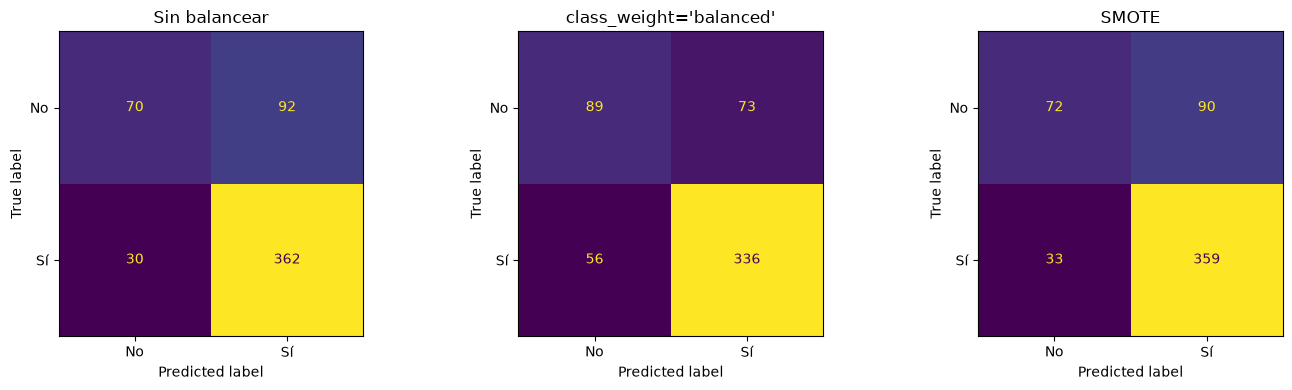

In [45]:
def metricas_test(modelo, X, y):
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    return {"Accuracy": (pred == y).mean(),
            "F1 macro": f1_score(y, pred, average="macro"),
            "F1 ponderado": f1_score(y, pred, average="weighted"),
            "F1 clase No": f1_score(y, pred, pos_label=0),
            "Recall No": recall_score(y, pred, pos_label=0),
            "Precision No": precision_score(y, pred, pos_label=0, zero_division=0),
            "Recall Sí": recall_score(y, pred, pos_label=1),
            "ROC-AUC": roc_auc_score(y, prob)}

tabla_test = pd.DataFrame({nom: metricas_test(gs.best_estimator_, X_te, y_te)
                           for nom, gs in resultados_gs.items()}).T
display(tabla_test.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nom, gs) in zip(axes, resultados_gs.items()):
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_te, y_te,
                                          display_labels=["No", "Sí"], ax=ax, colorbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

En prueba, el recall de 'No' es 0,432 sin balancear, 0,549 con class_weight y 0,444 con SMOTE; el F1 macro es 0,695, 0,709 y 0,697. class_weight gana recall a costa de precisión de 'No' (0,70 → 0,61), recall de 'Sí' (0,92 → 0,86) y accuracy (0,780 → 0,767). SMOTE casi no cambia nada frente al modelo base.

### 6.5 Diferencia

In [46]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

filas = []
for nom, gs in resultados_gs.items():
    cvr = cross_validate(clone(gs.best_estimator_), X_tr, y_tr, cv=rcv,
                         scoring=scoring_bal, n_jobs=-1)
    fila = {"variante": nom}
    for m in ["f1_macro", "recall_No", "precision_No", "accuracy", "roc_auc"]:
        v = cvr[f"test_{m}"]
        fila[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    filas.append(fila)
display(pd.DataFrame(filas).set_index("variante"))

,f1_macro,recall_No,precision_No,accuracy,roc_auc
variante,,,,,
Sin balancear,0.699 ± 0.018,0.449 ± 0.026,0.691 ± 0.034,0.780 ± 0.013,0.782 ± 0.021
class_weight='balanced',0.707 ± 0.016,0.566 ± 0.032,0.598 ± 0.028,0.761 ± 0.014,0.784 ± 0.021
SMOTE,0.703 ± 0.015,0.466 ± 0.029,0.681 ± 0.028,0.780 ± 0.011,0.781 ± 0.021


En 15 evaluaciones, la mejora de SMOTE en el recall de 'No' (0,466 vs 0,449) es menor que la desviación estándar (~0,03), así que puede ser ruido. La de class_weight (0,566 ± 0,032) es de ~4 desviaciones y sí es real, aunque su ganancia en F1 macro (0,707 vs 0,699) cae dentro del ruido (±0,016): es un intercambio de precisión por recall, no una mejora global.

### 6.6 Recomendacion sobre SMOTE

No se recomienda aplicar SMOTE: eleva el recall de 'No' solo ~0,01–0,02 (dentro del ruido), sin mejorar el F1 macro de forma clara, y complica el pipeline con datos sintéticos. Si detectar los rechazos es prioritario, es preferible class_weight='balanced', que sube el recall de 0,45 a 0,57 sin generar datos, aceptando ~2 puntos menos de accuracy.

Para la empresa hay dos costos distintos: enviar un cupón a quien lo va a rechazar (notificación inoportuna, que es lo que se quiere reducir) y no enviarlo a quien lo habría aceptado (oportunidad perdida). En Restaurante(<20) siete de cada diez conductores aceptan, así que un modelo que dijera "Sí" casi siempre acertaría ~70% sin evitar ninguna molestia. Por eso el recall de "No" (la proporción de rechazos que el sistema logra anticipar) es la métrica que realmente mide si el modelo ayuda a la empresa. El desbalance sí afecta al modelo base: con solo 29% de ejemplos "No", aprende a favorecer "Sí" y su recall de "No" es 0,43 frente a 0,92 para "Sí".

El balanceo con `class_weight='balanced'` sube el recall de "No" a 0,55 en prueba, pero cuesta recall de "Sí" (0,92 a 0,86) y precisión de "No" (0,70 a 0,61): se anticipan más rechazos y se pierden algunas aceptaciones. Si Ruta Alpes prioriza no molestar al conductor, conviene `class_weight`. Si prioriza no perder ventas, el modelo sin balancear ya es razonable. SMOTE no aporta una mejora clara en ninguno de los dos casos.

## 7. Tabla comparativa

In [48]:
modelos_comp = {
    "Regresión logística": modelos,
    "Árbol de decisión": arboles,
    "Random Forest": bosques,
}

filas = []
for cupon in splits:
    X_te, y_te = splits[cupon][1], splits[cupon][3]
    for nombre_mod, dic in modelos_comp.items():
        y_pred = dic[cupon].predict(X_te)
        p, r, f, _ = precision_recall_fscore_support(y_te, y_pred, labels=[0, 1], zero_division=0)
        f_macro = precision_recall_fscore_support(y_te, y_pred, average="macro", zero_division=0)[2]
        filas.append({
            ("", "Cupón"): cupon,
            ("", "Modelo"): nombre_mod,
            ("Clase No", "Recall"): r[0], ("Clase No", "Precisión"): p[0], ("Clase No", "F1"): f[0],
            ("Clase Sí", "Recall"): r[1], ("Clase Sí", "Precisión"): p[1], ("Clase Sí", "F1"): f[1],
            ("General", "F1 macro"): f_macro,
        })

tabla = pd.DataFrame(filas)
tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
tabla = tabla.set_index([("", "Cupón"), ("", "Modelo")])
tabla.index.names = ["Cupón", "Modelo"]

def resaltar_max(col):
    # Resalta el mejor modelo de cada métrica dentro de cada cupón
    es_max = col.groupby(level=0).transform("max") == col
    return ["font-weight: bold; background-color: #d4edda; color: black" if v else ""
            for v in es_max]

display(tabla.style.format("{:.3f}").apply(resaltar_max, axis=0))

La tabla corresponde al conjunto de prueba (796 filas en Cafetería y 554 en Restaurante(<20)). El mejor valor de cada métrica dentro de cada cupón aparece resaltado.

En Cafetería el Random Forest es el mejor en todas las métricas: F1 de 0,772 para "No" y 0,776 para "Sí" (F1 macro de 0,774), frente a ~0,69 de la regresión logística y del árbol, que quedan casi empatados entre sí.

En Restaurante(<20) el Random Forest tiene el mejor F1 macro (0,711 frente a 0,657 y 0,664) porque mejora justo donde los otros fallan: el recall de "No" pasa de ~0,37 a 0,568 y el F1 de "No" de ~0,48 a 0,586. El costo es menor recall de "Sí" (0,847 frente a 0,923) y menor precisión de "No" (0,605 frente a ~0,67): el modelo deja de ofrecer el cupón a algo más de 7 de cada 100 personas que lo habrían aceptado, a cambio de anticipar muchos más rechazos.

Se selecciona el Random Forest para los dos cupones. Para Ruta Alpes hay dos errores posibles: enviar un cupón a quien lo va a rechazar (una notificación inoportuna, que es justo el problema que la empresa quiere reducir) y no enviarlo a quien lo habría aceptado (una venta perdida). El Random Forest es el que mejor equilibra ambos, y en Restaurante(<20) es el único que detecta una parte razonable de los rechazos.

## 8. Variables más relevantes

Se identifican los factores que más influyen en la aceptación de cada cupón usando el Random Forest seleccionado en la sección 7. Se usa **importancia por permutación sobre el conjunto de prueba** (caída del ROC-AUC al desordenar una variable), porque la importancia por impureza sobrestima las variables con muchos valores (ver 5.5). Las variables one-hot de una misma variable original se permutan **juntas** para medir el aporte de la variable completa y no el de cada categoría por separado.

### 8.1 Importancia por permutación (agrupada)

In [49]:
def grupo_de(col):
    """Variable original a la que pertenece una columna (agrupa las dummies de los nominales)."""
    for nom in NOMINALES:
        if col.startswith(nom + "_"):
            return nom
    return col

def importancia_agrupada(modelo, X, y, n_repeats=30, seed=42):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    grupos = {}
    for c in X.columns:
        grupos.setdefault(grupo_de(c), []).append(c)

    filas = []
    for g, cols in grupos.items():
        caidas = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]   # permuta las columnas del grupo juntas
            caidas.append(base - roc_auc_score(y, modelo.predict_proba(Xp)[:, 1]))
        filas.append({"variable": g, "caida AUC": np.mean(caidas), "desv": np.std(caidas)})
    return pd.DataFrame(filas).set_index("variable").sort_values("caida AUC", ascending=False)

DEMOGRAFICAS = ["edad", "genero", "estado_civil", "tiene_hijos", "ocupacion", "educacion", "ingreso"]

imp_grupo = {}
for n, gs in bosques.items():
    X_tr, X_te, y_tr, y_te = splits[n]
    imp_grupo[n] = importancia_agrupada(gs.best_estimator_, X_te, y_te)
    print(f"\n{n} - 10 variables más relevantes (caída de ROC-AUC por permutación)")
    print(imp_grupo[n].head(10).round(4))
    print(f"Variables con caída <= 0.001: {(imp_grupo[n]['caida AUC'] <= 0.001).sum()} de {len(imp_grupo[n])}")


Cafeteria - 10 variables más relevantes (caída de ROC-AUC por permutación)
                      caida AUC    desv
variable                               
frecuencia_cafeteria     0.1866  0.0129
ocupacion                0.0370  0.0042
ingreso                  0.0242  0.0026
vigencia_cupon           0.0202  0.0068
educacion                0.0195  0.0025
edad                     0.0178  0.0026
frecuencia_bar           0.0177  0.0024
destino                  0.0172  0.0056
estado_civil             0.0165  0.0021
hora                     0.0141  0.0058
Variables con caída <= 0.001: 2 de 21



Restaurante(<20) - 10 variables más relevantes (caída de ROC-AUC por permutación)
                                 caida AUC    desv
variable                                          
vigencia_cupon                      0.0391  0.0101
ocupacion                           0.0217  0.0059
destino                             0.0189  0.0068
edad                                0.0185  0.0039
educacion                           0.0156  0.0043
hora                                0.0152  0.0082
ingreso                             0.0139  0.0047
frecuencia_restaurante_menos_20     0.0107  0.0041
frecuencia_comida_para_llevar       0.0099  0.0048
genero                              0.0077  0.0036
Variables con caída <= 0.001: 1 de 21


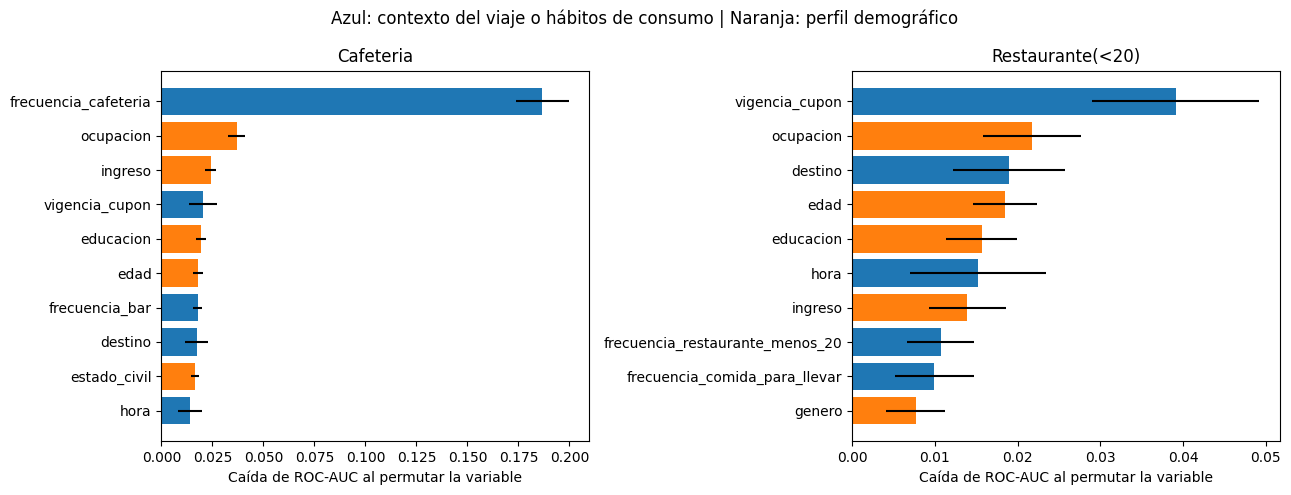

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (n, imp) in zip(axes, imp_grupo.items()):
    top = imp.head(10).iloc[::-1]
    colores = ["tab:orange" if v in DEMOGRAFICAS else "tab:blue" for v in top.index]
    ax.barh(top.index, top["caida AUC"], xerr=top["desv"], color=colores)
    ax.set_title(f"{n}")
    ax.set_xlabel("Caída de ROC-AUC al permutar la variable")
fig.suptitle("Azul: contexto del viaje o hábitos de consumo | Naranja: perfil demográfico")
plt.tight_layout()
plt.show()

En Cafetería domina `frecuencia_cafeteria`: al desordenarla el ROC-AUC cae 0,187, cinco veces más que la siguiente variable (`ocupacion`, 0,037). Le siguen `ingreso` (0,024), `vigencia_cupon` (0,020), `educacion` (0,020) y `edad` (0,018), con diferencias entre sí menores a dos desviaciones estándar, así que su orden exacto no es confiable. Solo 2 de 21 variables no aportan nada (caída ≤ 0,001).

En Restaurante(<20) el patrón es más plano y cambia el factor principal: `vigencia_cupon` (0,039) pasa al primer lugar, seguida de `ocupacion` (0,022), `destino` (0,019) y `edad` (0,019). La frecuencia de visita a restaurantes baratos pesa poco (`frecuencia_restaurante_menos_20`, 0,011), a diferencia de lo que ocurre con la cafetería. En Cafetería pesa más el hábito del conductor y en Restaurante(<20) pesa más el contexto del cupón.

En ambos cupones hay variables demográficas entre las 7 primeras (`ocupacion` en el puesto 2 en los dos casos), lo que es relevante para el análisis de sesgo.

### 8.2 Contraste con regresión logística y árbol de decisión

In [51]:
def resumen_modelo(serie):
    return serie.groupby(serie.index.map(grupo_de)).sum().sort_values(ascending=False)

filas = []
for n in splits:
    cols_X = splits[n][0].columns
    coef = pd.Series(np.abs(modelos[n].best_estimator_.named_steps["clf"].coef_[0]), index=cols_X)
    arb = pd.Series(arboles[n].best_estimator_.named_steps["clf"].feature_importances_, index=cols_X)
    filas.append(pd.DataFrame({
        "Cupón": n,
        "Random Forest (permutación)": imp_grupo[n].head(5).index,
        "Regresión logística (|coef|)": resumen_modelo(coef).head(5).index,
        "Árbol (impureza)": resumen_modelo(arb).head(5).index,
    }).assign(Puesto=range(1, 6)))
display(pd.concat(filas).set_index(["Cupón", "Puesto"]))

print("\nPuesto de las variables demográficas en el Random Forest")
for n, imp in imp_grupo.items():
    pos = {v: int(imp.index.get_loc(v)) + 1 for v in DEMOGRAFICAS}
    print(f"{n}: {pos}")

Random Forest (permutación)  \
Cupón            Puesto                               
Cafeteria        1             frecuencia_cafeteria   
                 2                        ocupacion   
                 3                          ingreso   
                 4                   vigencia_cupon   
                 5                        educacion   
Restaurante(<20) 1                   vigencia_cupon   
                 2                        ocupacion   
                 3                          destino   
                 4                             edad   
                 5                        educacion   

                        Regresión logística (|coef|)  \
Cupón            Puesto                                
Cafeteria        1              frecuencia_cafeteria   
                 2                           destino   
                 3                         ocupacion   
                 4                    vigencia_cupon   
                 5                              hora   
Restaurante(<20) 1                    vigencia_cupon   
                 2                         ocupacion   
                 3                       acompanante   
                 4                             clima   
                 5                           destino   

                                      Árbol (impureza)  
Cupón            Puesto                                 
Cafeteria        1                frecuencia_cafeteria  
                 2                             destino  
                 3                     misma_direccion  
                 4                                hora  
                 5                      vigencia_cupon  
Restaurante(<20) 1            tiempo_cupon_mayor_25min  
                 2                                hora  
                 3                      vigencia_cupon  
                 4                         acompanante  
                 5       frecuencia_comida_para_llevar


Puesto de las variables demográficas en el Random Forest
Cafeteria: {'edad': 6, 'genero': 14, 'estado_civil': 9, 'tiene_hijos': 17, 'ocupacion': 2, 'educacion': 5, 'ingreso': 3}
Restaurante(<20): {'edad': 4, 'genero': 10, 'estado_civil': 14, 'tiene_hijos': 17, 'ocupacion': 2, 'educacion': 5, 'ingreso': 7}


`frecuencia_cafeteria` es la variable más importante de Cafetería en los tres modelos, y `vigencia_cupon` y `destino` aparecen en el top 5 de los tres. En Restaurante(<20) `vigencia_cupon` es la primera para el Random Forest y la regresión logística, y la tercera para el árbol, y `ocupacion` aparece en el top 5 tanto del Random Forest como de la regresión logística. La variable principal del árbol, `tiempo_cupon_mayor_25min`, no aparece entre las 5 primeras del Random Forest, lo que sugiere que es una división específica del árbol individual, consistente con su menor estabilidad entre CV y prueba (sección 4.6).

Hay dos limitaciones al leer estos resultados: las variables correlacionadas se reparten la importancia y la subestiman al permutarlas, y las variables nominales agrupadas (como `ocupacion`, con 10 columnas) tienen más oportunidad de mostrar efecto que una variable binaria. Por eso la importancia indica asociación predictiva y no causalidad.

### 8.3 Dirección del efecto en la regresión logística

In [57]:
for n, gs in modelos.items():
    cols_X = splits[n][0].columns
    coef = pd.Series(gs.best_estimator_.named_steps["clf"].coef_[0], index=cols_X)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(8)
    tabla_coef = pd.DataFrame({"coeficiente": top,
                               "razón de odds": np.exp(top),
                               "efecto sobre aceptar": np.where(top > 0, "aumenta", "disminuye")})
    print(f"\n{n} - 8 coeficientes de mayor magnitud (variables estandarizadas)")
    print(tabla_coef.round(3))


Cafeteria - 8 coeficientes de mayor magnitud (variables estandarizadas)
                           coeficiente  razón de odds efecto sobre aceptar
frecuencia_cafeteria             0.966          2.627              aumenta
destino_Sin lugar urgente        0.506          1.659              aumenta
vigencia_cupon                   0.386          1.471              aumenta
hora                            -0.380          0.684            disminuye
misma_direccion                  0.255          1.290              aumenta
frecuencia_bar                  -0.224          0.800            disminuye
tiempo_cupon_mayor_15min        -0.207          0.813            disminuye
acompanante_Solo                -0.165          0.848            disminuye

Restaurante(<20) - 8 coeficientes de mayor magnitud (variables estandarizadas)
                                 coeficiente  razón de odds  \
vigencia_cupon                         0.542          1.720   
clima_Soleado                          0.341  

Los coeficientes están sobre variables estandarizadas, así que son comparables entre sí. Un coeficiente positivo aumenta la probabilidad de aceptar y uno negativo la disminuye. La razón de odds indica por cuánto se multiplica la probabilidad relativa de aceptar frente a no aceptar al subir una desviación estándar (o pasar de 0 a 1 en una variable binaria).

En Cafetería, el efecto más grande es `frecuencia_cafeteria` (+0,97, razón de odds de 2,6): quien visita más cafeterías acepta mucho más, lo que coincide con la exploración (18,8% de aceptación entre quienes nunca van frente a 64% o más entre quienes van con frecuencia). Siguen `destino_Sin lugar urgente` (+0,51), `vigencia_cupon` (+0,39, cupones de 1 día) y `hora` (-0,38: a horas más tardías se acepta menos). `frecuencia_bar` tiene signo negativo (-0,22): quien sale más a bares acepta menos cafetería, lo que sugiere sustitución de un plan por otro. Que `acompanante_Solo` sea negativo (-0,17) coincide con la exploración (43,8% viajando solo frente a 59,6% con amigos).

En Restaurante(<20) el factor principal cambia a `vigencia_cupon` (+0,54, razón de odds de 1,7: 83,2% de aceptación con vigencia de 1 día frente a 58,9% con 2 horas), seguido de `clima_Soleado` (+0,34: 76,8% frente a 38,8% con lluvia) y `destino_Sin lugar urgente` (+0,33). Viajar solo o con hijos reduce la aceptación, y `educacion` tiene signo negativo (-0,16), una variable del perfil del conductor. La frecuencia de visita pesa mucho menos que en Cafetería (+0,13).

En resumen, en Cafetería la aceptación depende sobre todo del hábito del conductor, y en Restaurante(<20) depende más del contexto del viaje y del cupón. Estos signos coinciden con la exploración, pero hay que leerlos con cuidado: variables correlacionadas como `destino` y `acompanante`, o `clima` y `temperatura`, se reparten el efecto, y la regularización l1 dejó 11 coeficientes en cero en Restaurante.

## 9. Predicciones sobre los datos de prueba

Se genera la etiqueta `acepta_cupon` para los registros no etiquetados de `Lab3_datos_Prueba` usando, para cada tipo de cupón, el Random Forest seleccionado en la sección 7.

### 9.1 Carga y preparación

In [52]:
RUTA_PRUEBA = './Data/Lab3_datos_Prueba.xlsx'
prueba = pd.read_excel(RUTA_PRUEBA)

print(prueba.shape)
print(prueba["cupon"].value_counts())
print("Tiene columna acepta_cupon:", "acepta_cupon" in prueba.columns)
print("Nulos por columna:")
print(prueba.isna().sum()[prueba.isna().sum() > 0])
print("Duplicados:", prueba.duplicated().sum())

(20, 25)
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64
Tiene columna acepta_cupon: False
Nulos por columna:
vehiculo    20
dtype: int64
Duplicados: 0


Los 20 registros (10 por cupón) no traen la columna `acepta_cupon`, que es lo que se debe predecir. `vehiculo` está 100% vacía en este archivo, igual que en el entrenamiento (~99%), y es una de las columnas que se eliminan. No hay duplicados ni otros nulos, así que no se requiere imputación adicional.

In [53]:
def preparar_prueba(filas, nombre):
    """Aplica a los registros de prueba exactamente la misma limpieza y codificación del entrenamiento."""
    f = filas.drop(columns=COLS_ELIMINAR).reset_index(drop=True)      # misma eliminación de columnas
    f["ocupacion"] = f["ocupacion"].where(f["ocupacion"].isin(principales), "Otras")  # mismas categorías de ocupación
    f["acepta_cupon"] = "No"   # etiqueta ficticia: solo permite reutilizar codificar(); se descarta enseguida

    # Se codifica junto con el conjunto de entrenamiento para que el one-hot (drop_first) use las mismas
    # categorías de referencia: con solo 10 filas faltarían categorías y las columnas no coincidirían.
    union = pd.concat([clean[nombre], f], ignore_index=True)
    cod = codificar(union).iloc[len(clean[nombre]):].drop(columns="acepta_cupon")

    columnas = splits[nombre][0].columns
    assert set(cod.columns) == set(columnas), "las columnas de prueba no coinciden con las de entrenamiento"
    return cod[columnas].reset_index(drop=True)

X_prueba = {}
for n, cup in [("Cafeteria", "Cafetería"), ("Restaurante(<20)", "Restaurante(<20)")]:
    filas = prueba[prueba["cupon"] == cup]
    X_prueba[n] = preparar_prueba(filas, n)
    X_prueba[n].index = filas.index
    print(n, X_prueba[n].shape, "| nulos:", int(X_prueba[n].isna().sum().sum()))

Cafeteria (10, 37) | nulos: 0
Restaurante(<20) (10, 37) | nulos: 0


| Decisión | Evidencia | Justificación |
| --- | --- | --- |
| Aplicar la misma eliminación de columnas y la misma agrupación de `ocupacion` | Constantes `COLS_ELIMINAR` y lista `principales` ya definidas en la sección 2 | El modelo se entrenó con 37 variables y espera exactamente esa representación |
| Codificar los registros de prueba junto con el conjunto limpio de entrenamiento | `get_dummies(drop_first=True)` sobre 10 filas elimina la categoría equivocada si falta alguna | Garantiza las mismas columnas y la misma categoría de referencia; luego se verifica con un `assert` que coinciden con las de entrenamiento |
| No imputar ni escalar a mano | El Pipeline ya incluye el imputador (moda) | Los nulos se tratan con las reglas aprendidas solo en entrenamiento |
| Mantener un modelo por tipo de cupón | Los comportamientos difieren entre cupones (sección 1.4) | Cada registro se predice con el modelo de su subconjunto |

### 9.2 Modelo final y predicciones

In [54]:
predicciones = pd.Series(index=prueba.index, dtype=object)
probabilidades = pd.Series(index=prueba.index, dtype=float)

for n in splits:
    X_tr, X_te, y_tr, y_te = splits[n]

    # Mismos hiperparámetros del mejor Random Forest, reentrenado con entrenamiento + prueba (más datos)
    final = clone(bosques[n].best_estimator_)
    final.fit(pd.concat([X_tr, X_te]), pd.concat([y_tr, y_te]))

    prob = final.predict_proba(X_prueba[n])[:, 1]
    probabilidades.loc[X_prueba[n].index] = prob
    predicciones.loc[X_prueba[n].index] = np.where(prob >= 0.5, "Sí", "No")

    print(f"{n}: {len(prob)} registros | acepta='Sí': {(prob >= 0.5).sum()} | 'No': {(prob < 0.5).sum()}")
    print("  Hiperparámetros:", bosques[n].best_params_)

Cafeteria: 10 registros | acepta='Sí': 6 | 'No': 4
  Hiperparámetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 15, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}


Restaurante(<20): 10 registros | acepta='Sí': 9 | 'No': 1
  Hiperparámetros: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}


Se usa el Random Forest en ambos cupones porque fue el mejor en ROC-AUC de CV y de prueba (sección 5.6). Antes de predecir se reentrena con los mismos hiperparámetros sobre entrenamiento + prueba (3.979 y 2.769 filas), porque ya se eligió el modelo y esos datos adicionales permiten un mejor ajuste final. La etiqueta se asigna con umbral 0,5 sobre la probabilidad de aceptación.

Resultado: Cafetería 6 'Sí' y 4 'No'; Restaurante(<20) 9 'Sí' y 1 'No'. Con solo 10 registros por cupón la proporción no es comparable con las tasas base (49,9% y 70,7%). Hay que recordar que en Restaurante(<20) el recall de 'No' es de ~0,55 (sección 6), así que el modelo puede estar dejando pasar rechazos.

### 9.3 Exportación

In [55]:
resultado = prueba.copy()
# La columna objetivo va en la misma posición que en el archivo de datos original
posicion = list(data.columns).index("acepta_cupon")
resultado.insert(posicion, "acepta_cupon", predicciones)

assert list(resultado.columns) == list(data.columns), "las columnas no coinciden con el archivo original"
assert resultado["acepta_cupon"].isin(["Sí", "No"]).all()

resultado.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8-sig")

leido = pd.read_csv("Lab3_datos_Prueba.csv")
print(leido.shape)
display(leido[["cupon", "acepta_cupon"]].assign(prob_si=probabilidades.round(3).values))

(20, 26)


,cupon,acepta_cupon,prob_si
0,Cafetería,No,0.483
1,Cafetería,Sí,0.829
2,Cafetería,Sí,0.820
3,Cafetería,Sí,0.896
4,Restaurante(<20),Sí,0.868
5,Restaurante(<20),Sí,0.944
6,Restaurante(<20),No,0.226
7,Restaurante(<20),Sí,0.820
8,Restaurante(<20),Sí,0.910
9,Cafetería,No,0.174


Se exportó `Lab3_datos_Prueba.csv` con 20 filas y 26 columnas: las 25 del archivo de prueba más `acepta_cupon` ('Sí' / 'No'), en la misma posición que en el archivo de datos original. Se guarda con codificación `utf-8-sig` para que Excel muestre bien los acentos, y se relee para comprobar su contenido.

## 10. Análisis de resultados

### 10.1 ¿Qué características se relacionan más con la aceptación?

En Cafetería la característica más relacionada es el hábito del conductor: `frecuencia_cafeteria`. Al desordenarla, el ROC-AUC cae 0,187, cinco veces más que la siguiente variable. Solo acepta el 18,8% de quienes nunca van a cafeterías, frente a 64% o más entre quienes van con frecuencia. Después pesan el contexto del viaje (destino "sin lugar urgente", 58,0% de aceptación frente a 36,1% cuando va a casa; la hora, con 64,0% a las 10:00 a.m. y 41,2% a las 6:00 p.m.; y la vigencia del cupón, 58,4% con 1 día frente a 43,2% con 2 horas) y el perfil (ocupación, ingreso, educación y edad).

En Restaurante(<20) pesa más el contexto del cupón. La variable principal es `vigencia_cupon` (caída de ROC-AUC de 0,039; 83,2% de aceptación con 1 día frente a 58,9% con 2 horas), seguida de ocupación, destino, edad y hora. El clima también separa mucho (76,8% con sol frente a 38,8% con lluvia), aunque el modelo reparte ese efecto con la temperatura. La frecuencia de visita pesa poco (aceptación de 55,6% entre quienes nunca van a restaurantes baratos y 76,0% entre quienes van más de 8 veces).

### 10.2 ¿Hay variables redundantes o poco informativas?

Se revisan las correlaciones entre pares de variables y las variables con menor importancia por permutación.

In [58]:
for n in splits:
    X_tr = splits[n][0]
    corr = X_tr.corr().abs()
    pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
    print(f"\n{n} - 6 pares de variables más correlacionados (|r|)")
    print(pares.head(6).round(2))
    print(f"\n{n} - 6 variables con menor importancia por permutación")
    print(imp_grupo[n].tail(6).round(4))


Cafeteria - 6 pares de variables más correlacionados (|r|)
destino_Sin lugar urgente  acompanante_Solo    0.76
hora                       destino_Trabajo     0.74
clima_Nevado               clima_Soleado       0.74
temperatura                clima_Nevado        0.69
                           clima_Soleado       0.68
destino_Sin lugar urgente  destino_Trabajo     0.57
dtype: float64

Cafeteria - 6 variables con menor importancia por permutación
                          caida AUC    desv
variable                                   
temperatura                  0.0065  0.0026
tiene_hijos                  0.0061  0.0013
misma_direccion              0.0045  0.0017
clima                        0.0016  0.0011
tiempo_cupon_mayor_25min     0.0003  0.0017
tiempo_cupon_mayor_15min    -0.0017  0.0040

Restaurante(<20) - 6 pares de variables más correlacionados (|r|)
clima_Nevado               clima_Soleado       0.81
hora                       destino_Trabajo     0.77
temperatura                

Hay redundancia por diseño de la encuesta. `misma_direccion` y `direccion_opuesta` eran complementarias y ya se eliminó una (sección 2). `clima` y `temperatura` están muy relacionadas (|r| entre 0,66 y 0,81 con las columnas de clima): Nevado solo ocurre a 30°F y Lluvioso a 55°F. `destino_Trabajo` y `hora` también (0,74 y 0,77), porque los viajes al trabajo se concentran en ciertas horas, y `destino_Sin lugar urgente` con `acompanante_Solo` (0,76 en Cafetería y 0,65 en Restaurante).

Las menos informativas son `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` (caída de ROC-AUC prácticamente cero o negativa, dentro del ruido en ambos cupones), `misma_direccion` (0,005 y 0,001), `tiene_hijos` (0,006 y 0,003), `clima` y `temperatura`. Hay que ser prudente: una variable correlacionada con otra puede mostrar poca importancia porque la otra ya aporta la misma información (es el caso de `clima` y `temperatura`), no porque sea inútil. Las candidatas más claras para descartar son las dos de tiempo del cupón.

### 10.3 ¿Difieren los modelos entre Cafetería y Restaurante(<20)?

Sí. El Random Forest obtiene ROC-AUC de 0,841 en Cafetería y 0,784 en Restaurante(<20), F1 macro de 0,774 y 0,711, y recall de "No" de 0,762 y 0,568. Las razones más probables son tres:

1. El desbalance. Cafetería está al 50/50, mientras que en Restaurante(<20) solo el 29,3% son "No", así que el modelo ve menos ejemplos de rechazo y los aprende peor. Su accuracy (0,77) está solo unos 6 puntos por encima de responder siempre "Sí" (70,8%).
2. Una señal más difusa. En Cafetería existe un predictor fuerte (el hábito de visita). En Restaurante no hay ninguno equivalente, y la aceptación se reparte entre vigencia, clima, destino y hora.
3. Variables que faltan. En ninguno de los dos se tiene el precio, el descuento ni la distancia real al local. Seguramente pesan más en Restaurante, y quedan por fuera del modelo.

También cambia el efecto de algunas variables: `direccion_opuesta` aumenta la aceptación en Restaurante (72,3% frente a 63,5%) y la disminuye en Cafetería (49,2% frente a 53,0%), por lo que se justifica entrenar un modelo para cada cupón.

### 10.4 ¿Mejoró el balanceo de clases en Restaurante(<20)?

No de forma clara. En validación cruzada el F1 macro fue de 0,7005 sin balancear, 0,7113 con `class_weight='balanced'` y 0,7085 con SMOTE. En prueba, el recall de "No" fue de 0,432, 0,549 y 0,444, y el F1 macro de 0,695, 0,709 y 0,697. Repetida la validación cruzada 15 veces, la mejora de SMOTE en el recall de "No" (0,466 frente a 0,449) es menor que la desviación estándar (~0,03), así que puede ser ruido. `class_weight` sí sube el recall de forma real (0,566 ± 0,032), pero a costa de precisión y de recall de "Sí", y su ganancia en F1 macro queda dentro del ruido. En conclusión, el balanceo cambia la forma de equivocarse del modelo, no lo mejora globalmente. No se recomienda SMOTE, y `class_weight` solo si detectar rechazos es la prioridad.

### 10.5 Reglas del árbol y del Random Forest

Primeros niveles de los árboles de decisión:

In [59]:
from sklearn.tree import export_text

for n, gs in arboles.items():
    clf = gs.best_estimator_.named_steps["clf"]
    print(f"\n{n} - primeros 3 niveles del árbol")
    print("(frecuencia_*: 0=nunca, 1=menos de 1, 2=1 a 3, 3=4 a 8, 4=más de 8; vigencia_cupon: 0=2 horas, 1=1 día)")
    print(export_text(clf, feature_names=list(splits[n][0].columns), class_names=["No", "Sí"], max_depth=3))


Cafeteria - primeros 3 niveles del árbol
(frecuencia_*: 0=nunca, 1=menos de 1, 2=1 a 3, 3=4 a 8, 4=más de 8; vigencia_cupon: 0=2 horas, 1=1 día)
|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- educacion <= 1.50
|   |   |   |   |--- class: No
|   |   |   |--- educacion >  1.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- class: No
|   |--- ingreso >  5.50
|   |   |--- destino_Sin lugar urgente <= 0.50
|   |   |   |--- class: No
|   |   |--- destino_Sin lugar urgente >  0.50
|   |   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |   |--- class: No
|   |   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |   |--- class: No
|--- frecuencia_cafeteria >  0.50
|   |--- destino_Sin lugar urgente <= 0.50
|   |   |--- misma_direccion <= 0.50
|   |   |   |--- frecuencia_cafeteria <= 1.50
|   |   |   |   |--- truncated bra

En Cafetería el árbol empieza dividiendo por `frecuencia_cafeteria <= 0,5`, es decir, por quienes nunca visitan cafeterías. Esa rama termina casi siempre en "No" (por ejemplo, nunca visita cafeterías y tiene ingreso bajo o no va sin urgencia: rechaza). Para quienes sí van, la decisión depende de si el destino es "sin lugar urgente", de la frecuencia de visita (1 a 3 veces o más), de la hora y de la vigencia del cupón. Con el Random Forest se llega a la misma conclusión por importancia de variables: `frecuencia_cafeteria` domina con diferencia, seguida de ocupación, ingreso, vigencia, educación y edad.

En Restaurante(<20) el árbol empieza por `tiempo_cupon_mayor_25min`. Si el local está a más de 25 minutos y el conductor no va solo, predice "Sí" directamente. Si va solo y sale mucho a bares, predice "No". Con cupones de 1 día en días fríos (temperatura de 42°F o menos) y sin costumbre de ir a cafeterías, predice "No". El Random Forest, en cambio, pone primero la vigencia del cupón, la ocupación y el destino.

Esta interpretación tiene una utilidad clara: las reglas se pueden explicar a alguien del negocio sin saber de modelos ("quien nunca va a cafeterías casi nunca acepta"), y permiten revisar si el modelo hace sentido. Pero tiene limitaciones:
- Es inestable. El árbol de Restaurante bajó de 0,743 en validación cruzada a 0,707 en prueba, y su variable principal (`tiempo_cupon_mayor_25min`) ni siquiera aparece entre las más importantes del Random Forest, lo que sugiere una división particular de esa muestra.
- Solo se muestran los primeros tres niveles, y el árbol real es más profundo.
- La importancia de variables dice cuánto pesan, no en qué dirección. Para eso se usan los coeficientes de la regresión logística (sección 8.3).
- Las variables correlacionadas se reparten la importancia y los cortes sobre variables ordinales (como la hora) dependen de la codificación numérica elegida.

### 10.6 ¿Cómo integrar el modelo en la aplicación en tiempo real?

Una propuesta concreta sería esta:
1. Entrenar y guardar el pipeline completo (imputación y Random Forest) por cada tipo de cupón, de modo que las mismas transformaciones se apliquen en producción.
2. Cuando el conductor se acerca a locales con cupones disponibles, la aplicación arma las variables de contexto (hora, destino, clima, acompañante, desvío en minutos, vigencia) y las del perfil guardado, y consulta ambos modelos. Un Random Forest de 300 a 500 árboles responde en milisegundos, por lo que cabe en el flujo de navegación.
3. Se compara la probabilidad de aceptación de cada cupón con un umbral y se muestra el de mayor probabilidad solo si lo supera. Si ninguno lo supera, no se muestra nada. Para Restaurante(<20) el umbral puede ser mayor que 0,5, porque el modelo ya tiende a decir "Sí" y enviar menos notificaciones reduce la molestia.
4. Se limita la frecuencia de notificaciones y no se muestra ninguna que distraiga al conductor mientras conduce.
5. Se registra qué se mostró y si se aceptó, para reentrenar y para detectar si el modelo se degrada. Se puede validar con una prueba A/B contra la estrategia actual de enviar el mismo cupón a todos.

### 10.7 Limitaciones de un sistema automático que decide según el perfil demográfico

- Calidad del modelo. En Cafetería el modelo acierta ~77% de las veces: uno de cada cuatro cupones se mostraría o se ocultaría mal. En Restaurante(<20) solo detecta el 57% de los rechazos.
- Datos. Si la aceptación proviene de una encuesta, como el conjunto original en que se basa este laboratorio, mide una intención declarada y no un comportamiento real. Faltan variables de peso como el precio, el descuento y la distancia real.
- Cambios en el tiempo. Los hábitos, las estaciones y la oferta de locales cambian, y un modelo entrenado con datos de un momento puede perder precisión.
- Retroalimentación. Si el sistema solo aprende de lo que muestra, no sabe qué habría pasado con los cupones que decidió no mostrar.
- Privacidad y transparencia. Usa datos personales del conductor, y este no sabe por qué se le muestra una oferta ni puede corregirla.
- Seguridad vial. Una oferta mal puesta durante la conducción distrae.

### 10.8 Fuentes de sesgo e implicaciones para otros usos

Hay al menos cuatro fuentes de sesgo:
1. Representatividad de los datos. Quienes respondieron pueden no representar a todos los conductores. En el cuaderno, además, las ocupaciones poco frecuentes se agruparon en "Otras", y la edad ya viene en tramos amplios (por ejemplo "50 o más"), lo que borra diferencias dentro de esos grupos.
2. Variables que funcionan como sustitutos. Ocupación, ingreso y educación se relacionan con el nivel socioeconómico, y estado civil y tiene_hijos con el momento de vida. Aunque se quitara el género, el modelo podría reproducir diferencias asociadas a él. En nuestros resultados, la ocupación es la segunda variable más importante en ambos cupones, y edad, educación e ingreso están entre las siete primeras.
3. Sesgo en lo que se mide. La aceptación depende del descuento y del local, que no están en los datos, y el modelo puede atribuirle al perfil del conductor efectos que en realidad vienen de la oferta.
4. Sesgo en el rendimiento. No se midió si el modelo falla más con algún grupo. Con un ROC-AUC de 0,78 a 0,84 hay errores, y podrían concentrarse en ciertos perfiles.

Si el mismo tipo de modelo se usara para precios dinámicos, el problema cambia de naturaleza. Dejaría de ser "qué cupón mostrar" (un beneficio opcional) para convertirse en "cuánto cobrar a cada persona", lo que puede significar cobrar más a quien se estima más dispuesto a pagar, con perfiles demográficos de por medio. Eso puede constituir discriminación indirecta, con consecuencias éticas y legales. Antes de usarlo así habría que medir el rendimiento por grupo, comparar el modelo con y sin variables demográficas (si el AUC casi no cae, no vale la pena el riesgo), preferir variables de contexto y dar al usuario transparencia y supervisión humana.

## Uso de herramientas de IA generativa

### Declaración del uso

Se usó Claude (Anthropic) como ayuda conceptual y de explicación teórica para aclarar dudas puntuales sobre los resultados del laboratorio.

### Prompts utilizados

1. ¿Crees que ya están bien limpiados los datos?
2. ¿Qué sesgos puede introducir usar edad, género o ingreso para personalizar cupones, y qué pasaría si se usara para precios dinámicos?
3. ¿Por qué la importancia por impureza y la importancia por permutación dan rankings distintos?
4. ¿Por qué class_weight='balanced' subió el recall de "No" pero SMOTE casi no cambió nada?
5. ¿El ROC-AUC de entrenamiento de 1,00 frente a 0,84 en validación es sobreajuste, y por qué igual se eligió ese modelo?
6. ¿Por qué se usó ROC-AUC para elegir hiperparámetros y F1 macro en la sección de balanceo?
7. ¿Por qué se reentrena el modelo con train y test antes de predecir, y tiene sentido usar el umbral 0,5 con clases desbalanceadas?

### Análisis crítico del resultado

Casi todas las explicaciones que recibimos se pudieron comprobar con nuestros propios resultados, y coincidían. Por ejemplo, nos dijeron que algunas medidas de importancia "inflan" las variables que tienen muchos valores distintos. En el cuaderno pasa exactamente eso: la frecuencia de visita a cafeterías sale con un peso de 0,063 en Restaurante según un método y de apenas 0,002 según el otro. También nos explicaron que un modelo puede acertar el 100% con los datos que ya vio y mucho menos con datos nuevos (sobreajuste). Eso se ve en el Random Forest, que llega a 1,00 en entrenamiento y a 0,84 en validación. Como la prueba da casi lo mismo que la validación (0,841), el resultado es confiable. Y la diferencia entre las dos medidas que usamos, ROC-AUC y F1, se ve en la sección 6: darle más peso a la clase "No" no cambió el ROC-AUC, pero sí hizo que el modelo encontrara más rechazos.

Cuando preguntamos si los datos ya estaban bien limpiados, la respuesta fue que sí, y lo comprobamos nosotros en los datos: las 25 ocupaciones no tienen errores de escritura, no hay espacios sobrantes en ninguna columna y la temperatura solo toma los tres valores esperados. También quedaron señalados tres detalles que decidimos no corregir.

El primero son 7 casos de filas idénticas en todas las variables pero con respuestas distintas: uno aceptó el cupón y el otro no. En una encuesta es normal que dos personas parecidas respondan distinto. Como los datos no traen un identificador de persona, no hay forma de saber cuál de las dos respuestas es la equivocada, y borrarlas solo escondería esa variación real. Lo dejamos así. La consecuencia es que ningún modelo puede acertar el 100% con estos datos, porque parte de la respuesta no depende de lo que se midió.

El segundo son 7 filas donde el conductor dice no tener hijos pero viaja con "hijo(s)". Puede ser un error de la persona al responder, pero también puede ser que viaje con sobrinos o nietos. Como no podemos saber cuál es el caso y son 7 filas entre casi 6.800, dejarlas no cambia los resultados.

El tercero es la lista de ocupaciones que se agrupan como "Otras", que se calculó con todos los datos antes de separar entrenamiento y prueba. Esa lista solo usa cuántas veces aparece cada ocupación, nunca la respuesta del conductor, así que el modelo no ve información que no debería. Lo más estricto habría sido calcularla solo con los datos de entrenamiento, pero corregirlo obligaba a rehacer todo el cuaderno y a revisar las cifras de los textos, y el efecto esperado era muy pequeño. Preferimos dejarlo y dejarlo explicado.

Hubo cosas que las respuestas no resolvían del todo. Nos dijeron que SMOTE (una técnica que inventa ejemplos nuevos de la clase minoritaria) casi no ayudó porque los ejemplos inventados aportan poco en datos como los nuestros, que son sobre todo categorías. Nos pareció razonable, pero es una hipótesis: no hicimos ninguna prueba para confirmarla. Sobre los sesgos, la respuesta fue general. Sabemos que la ocupación, la edad y el ingreso pesan en el modelo, pero no medimos si el modelo falla más con un grupo de personas que con otro, así que no podemos decir si es injusto con alguien. Y sobre el umbral de 0,5 (la probabilidad desde la cual el modelo dice "Sí"), la respuesta sugería probar otros valores. No lo hicimos, y con solo 10 casos de prueba por cupón tampoco habríamos podido saber cuál es mejor.

Estas respuestas no cambiaron lo que ya habíamos decidido, como quedarnos con el Random Forest o preferir dar más peso a la clase "No" en vez de usar SMOTE. Nos sirvieron para entender mejor por qué esas decisiones tenían sentido. Lo que vimos en clase sobre validación cruzada, sobreajuste y desbalance de clases fue lo que nos permitió revisar si las explicaciones tenían sentido.

### Aportes propios

Se hizo el trabajo del laboratorio: explorar los datos, limpiarlos, entrenar los tres tipos de modelo para cada cupón, probar el balanceo de clases y armar la tabla que compara los modelos. En cada paso escribimos por qué tomamos cada decisión, con base en lo que mostraban los datos. Las preguntas que le hicimos a la herramienta salieron de dudas sobre esos resultados, y antes de usar las respuestas las comparamos con lo que mostraba el cuaderno.

Con este proceso entendimos mejor tres cosas. Primero, que el ranking de variables importantes cambia según cómo se calcule, así que conviene mirar más de un método. Segundo, que una sola métrica no alcanza para juzgar si un modelo detecta bien la clase menos frecuente. Y tercero, que usar datos personales como la edad o el ingreso para decidir qué oferta mostrar tiene riesgos que hay que revisar antes de usarlo en una aplicación real.